In [48]:
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt
import scanpy as sc
from matplotlib.lines import Line2D
from matplotlib.gridspec import GridSpec

def plot_spatial_compact(
    ad,
    color="leiden_2",
    groupby="sample_id",
    spot_size=18,
    cols=3,
    height=8,
    legend_col_width=1.2,
    palette=None,          # <- NEW: dict {category: "#hex"} or list in desired order
):
    # --- categories from the FULL object (freeze order) ---
    cats = ad.obs[color].astype("category").cat.categories

    # --- build a shared color list in that order ---
    if isinstance(palette, dict):
        cols_list = [palette[c] for c in cats]
    elif isinstance(palette, (list, tuple)):
        if len(palette) < len(cats):
            raise ValueError("Palette list shorter than number of categories.")
        cols_list = list(palette)[:len(cats)]
    elif f"{color}_colors" in ad.uns:
        # reuse existing palette if present on the full object
        cols_list = list(ad.uns[f"{color}_colors"])
        if len(cols_list) != len(cats):
            raise ValueError(f"{color}_colors length does not match categories.")
    else:
        base = sc.pl.palettes.default_64 if hasattr(sc.pl.palettes, "default_64") else sc.pl.palettes.default_102
        reps = int(np.ceil(len(cats) / len(base)))
        cols_list = (base * reps)[:len(cats)]

    # store on the full object too (handy if you plot elsewhere later)
    ad.uns[f"{color}_colors"] = cols_list

    # --- layout ---
    sids = list(ad.obs[groupby].unique())
    n = len(sids)
    rows = int(np.ceil(n / cols))

    panel_w = height * cols * 0.6 / rows
    fig_w = panel_w + legend_col_width
    fig = plt.figure(figsize=(fig_w, height), constrained_layout=False)

    gs = GridSpec(
        rows, cols + 1, figure=fig,
        width_ratios=[1]*cols + [legend_col_width / (fig_w - legend_col_width)],
        wspace=0.02, hspace=0.02
    )

    # --- panels ---
    for i, sid in enumerate(sids):
        r, c = divmod(i, cols)
        ax = fig.add_subplot(gs[r, c])

        ad_sub = ad[ad.obs[groupby] == sid].copy()

        # CRUCIAL: force identical categories & palette on each subset
        ad_sub.obs[color] = ad_sub.obs[color].astype("category")
        ad_sub.obs[color] = ad_sub.obs[color].cat.set_categories(cats)
        ad_sub.uns[f"{color}_colors"] = cols_list

        sc.pl.spatial(
            ad_sub, color=color, spot_size=spot_size,
            show=False, ax=ax, legend_loc=None, frameon=False, title=str(sid)
        )
        ax.set_xlabel(""); ax.set_ylabel("")
        ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

    # blank unused
    for j in range(n, rows*cols):
        r, c = divmod(j, cols)
        fig.add_subplot(gs[r, c]).axis("off")

    # --- legend ---
    ax_leg = fig.add_subplot(gs[:, -1])
    ax_leg.axis("off")
    handles = [
        Line2D([0], [0], marker='o', color='w',
               markerfacecolor=cols_list[k], markersize=7, label=str(cat))
        for k, cat in enumerate(cats)
    ]
    ax_leg.legend(handles=handles, title=color, frameon=False, loc="center left")

    fig.subplots_adjust(left=0.01, right=0.98, top=0.98, bottom=0.02, wspace=0.02, hspace=0.02)
    plt.show()

import numpy as np
import matplotlib.pyplot as plt
import scanpy as sc
from matplotlib.gridspec import GridSpec
from matplotlib.colors import Normalize

def plot_spatial_genes_compact(
    ad,
    genes,
    groupby="sample_id",
    spot_size=18,
    cols=3,
    height=8,
    cmap="magma",          # any matplotlib colormap
    log1p=False,           # log1p-transform before plotting
    robust=True,           # use robust 2–98% limits instead of min/max
    vmin=None, vmax=None,  # override global color limits if you want
    nan_color="lightgray", # background for zero/NaN
    title_suffix="",
):
    """
    Plot per-sample spatial maps for one or multiple genes (continuous).
    Uses a shared color scale across all samples for each gene.
    """

    # ensure genes is a list
    genes = [genes] if isinstance(genes, str) else list(genes)
    sids  = list(ad.obs[groupby].unique())
    nS, nG = len(sids), len(genes)

    # grid: rows = samples, cols = genes + 1 legend column
    cols_total = nG + 1
    rows = int(np.ceil(nS))
    fig = plt.figure(figsize=(height * cols_total * 0.6, height), constrained_layout=False)
    gs  = GridSpec(rows, cols_total, figure=fig, width_ratios=[1]*nG + [0.25],
                   wspace=0.03, hspace=0.03)

    for gi, g in enumerate(genes):
        if g not in ad.var_names:
            print(f"⚠️ Gene '{g}' not in var_names; skipping.")
            continue

        # collect values across ALL samples to set shared limits
        vals = ad[:, g].X
        vals = vals.toarray().ravel() if hasattr(vals, "toarray") else np.asarray(vals).ravel()
        if log1p: vals = np.log1p(vals)

        if vmin is None or vmax is None:
            if robust:
                lo, hi = np.nanpercentile(vals, [2, 98])
            else:
                lo, hi = np.nanmin(vals), np.nanmax(vals)
        else:
            lo, hi = vmin, vmax
        if hi <= lo:  # degenerate case
            hi = lo + 1e-9
        norm = Normalize(vmin=lo, vmax=hi)

        # draw per-sample panels for this gene
        for si, sid in enumerate(sids):
            ax = fig.add_subplot(gs[si, gi]) if rows > 1 else fig.add_subplot(gs[0, gi])
            ad_sub = ad[ad.obs[groupby] == sid].copy()

            # precompute color values so Scanpy respects global norm
            v = ad_sub[:, g].X
            v = v.toarray().ravel() if hasattr(v, "toarray") else np.asarray(v).ravel()
            if log1p: v = np.log1p(v)
            # map to colors
            cmap_obj = plt.get_cmap(cmap)
            rgba = cmap_obj(norm(v))
            # make zeros / NaNs pale
            mask = ~np.isfinite(v) | (v <= 0)
            rgba[mask, :3] = plt.matplotlib.colors.to_rgb(nan_color)  # set color
            rgba[mask, 3]  = 1.0                                     # opaque

            # Scanpy trick: provide precomputed colors via obs (as hex)
            import matplotlib.colors as mcolors
            hex_colors = [mcolors.to_hex(c) for c in rgba]
            ad_sub.obs[f"__{g}__colors"] = hex_colors

            sc.pl.spatial(
                ad_sub,
                color=f"__{g}__colors",           # plot with our precomputed colors
                spot_size=spot_size,
                show=False,
                ax=ax,
                title=f"{sid}" + (f" • {title_suffix}" if title_suffix else ""),
                frameon=False,
                legend_loc=None,
            )
            ax.set_xlabel(""); ax.set_ylabel("")
            ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

        # add a colorbar column only once per gene
        cb_ax = fig.add_subplot(gs[:, -1]) if rows > 1 else fig.add_subplot(gs[0, -1])
        if gi == nG - 1:  # only draw once (last gene) to avoid redraw
            cb_ax.axis("off")
            sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
            sm.set_array([])
            cbar = fig.colorbar(sm, ax=cb_ax, fraction=0.8)
            cbar.set_label(f"{'log1p(' if log1p else ''}{genes[-1]}{')' if log1p else ''}", rotation=90)

    fig.subplots_adjust(left=0.02, right=0.98, top=0.96, bottom=0.02, wspace=0.02, hspace=0.02)
    plt.show()


def plot_spatial_any(
    ad,
    feature,
    **kwargs
):
    """
    Convenience dispatcher:
      - If `feature` is a column in .obs (categorical), call plot_spatial_compact
      - If `feature` is a gene (in .var_names), call plot_spatial_genes_compact
    """
    if feature in ad.obs.columns and pd.api.types.is_categorical_dtype(ad.obs[feature]):
        return plot_spatial_compact(ad, color=feature, **kwargs)
    elif feature in ad.var_names:
        return plot_spatial_genes_compact(ad, genes=feature, **kwargs)
    else:
        raise ValueError(f"'{feature}' not found as categorical obs or gene.")

import matplotlib.pyplot as plt
import scanpy as sc
import numpy as np

def plot_spatial_highlight(
    ad,
    color="rbd_domain_0.5",
    highlight=None,            # one or multiple categories to highlight
    groupby="sample_id",
    spot_size=18,
    cols=3,
    height=8,
    base_color="lightgrey",
    highlight_color=None,      # auto from palette if None
):
    """
    Plot one or several clusters highlighted in color, others grey.
    """

    if highlight is None:
        raise ValueError("Please specify at least one value in `highlight`")

    # make a copy to avoid modifying original
    ad = ad.copy()
    vals = ad.obs[color].astype(str)

    # identify highlight set
    highlight = [highlight] if isinstance(highlight, str) else list(highlight)
    mask = vals.isin(highlight)

    # define colors
    # reuse existing palette if present
    if f"{color}_colors" in ad.uns:
        pal = dict(zip(ad.obs[color].cat.categories, ad.uns[f"{color}_colors"]))
    else:
        base = getattr(sc.pl.palettes, "default_102", sc.pl.palettes.vega_20)
        cats = ad.obs[color].astype("category").cat.categories
        reps = int(np.ceil(len(cats)/len(base)))
        all_colors = (base * reps)[:len(cats)]
        pal = dict(zip(cats, all_colors))

    # pick one highlight color (first of list)
    if highlight_color is None:
        highlight_color = pal.get(highlight[0], "#d62728")  # fallback red

    # new column for plotting
    ad.obs["_highlight_plot_"] = np.where(mask, highlight[0], "other")
    ad.obs["_highlight_plot_"] = ad.obs["_highlight_plot_"].astype("category")

    # define palette for two classes: highlighted + grey
    palette = {"other": base_color, highlight[0]: highlight_color}

    # use your existing compact plot function
    plot_spatial_compact(
        ad,
        color="_highlight_plot_",
        groupby=groupby,
        spot_size=spot_size,
        cols=cols,
        height=height,
        palette=palette
    )

import numpy as np
import os
import matplotlib.pyplot as plt
import scanpy as sc

def _flip_y_inplace(ad):
    """Flip Y in .obsm['spatial'] so 'up' is up."""
    XY = ad.obsm["spatial"].copy()
    XY[:, 1] = XY[:, 1].max() - XY[:, 1]
    ad.obsm["spatial"] = XY
    return ad

def plot_spatial_highlight(
    adata,
    color="rbd_domain_0.5",
    highlight=None,
    groupby="sample_id",
    spot_size=18,
    cols=3,
    height=7,
    grey="#D9D9D9",
    cmap_highlight=None,
    flip_y=True,          # <- NEW: flip coordinates, not axes
    fix_limits=True       # <- NEW: keep consistent x/y limits across panels
):
    assert highlight is not None, "Provide a `highlight` category to emphasize."
    cats = adata.obs[color].astype("category").cat.categories
    sids = list(adata.obs[groupby].unique())
    n, rows = len(sids), int(np.ceil(len(sids)/cols))

    # choose highlight color
    if cmap_highlight is None and f"{color}_colors" in adata.uns and highlight in cats:
        hl_col = adata.uns[f"{color}_colors"][list(cats).index(highlight)]
    else:
        hl_col = cmap_highlight or "#3949ab"

    # global limits (after potential flip) so all axes are identical
    if fix_limits:
        ad_tmp = adata.copy()
        if flip_y: _flip_y_inplace(ad_tmp)
        X, Y = ad_tmp.obsm["spatial"][:,0], ad_tmp.obsm["spatial"][:,1]
        xlim = (X.min(), X.max())
        ylim = (Y.min(), Y.max())
        del ad_tmp
    else:
        xlim = ylim = None

    fig_w = cols * (height * 0.7); fig_h = height
    fig, axs = plt.subplots(rows, cols, figsize=(fig_w, fig_h), squeeze=False)
    for ax in axs.flat: ax.set_axis_off()

    for i, sid in enumerate(sids):
        r, c = divmod(i, cols)
        ax = axs[r, c]
        ad_sub = adata[adata.obs[groupby] == sid].copy()
        if flip_y: _flip_y_inplace(ad_sub)

        # masks
        mask_hi = (ad_sub.obs[color] == highlight)
        mask_lo = ~mask_hi

        # background (grey)
        if mask_lo.sum():
            sc.pl.spatial(ad_sub[mask_lo], color=None, spot_size=spot_size,
                          show=False, ax=ax, frameon=False)
            coll = ax.collections[-1]
            coll.set_facecolor(grey); coll.set_edgecolor("none")

        # highlight (colored)
        if mask_hi.sum():
            plt.rcParams["scatter.marker"] = "."
            plt.rcParams["patch.linewidth"] = 0

            sc.pl.spatial(ad_sub[mask_hi], color=None, spot_size=spot_size,
                          show=False, ax=ax, frameon=False)
            coll = ax.collections[-1]
            coll.set_facecolor(hl_col); coll.set_edgecolor("none")

        # lock limits so panels align
        if xlim: ax.set_xlim(*xlim)
        if ylim: ax.set_ylim(*ylim)

        ax.set_title(f"{sid} • {color}={highlight}", fontsize=10)

    # blank unused
    for j in range(n, rows*cols):
        r, c = divmod(j, cols)
        axs[r, c].axis("off")

    plt.tight_layout()
    return fig, axs



In [2]:
adata = sc.read_h5ad('../data/mtDNA_DSB_subset_rbd_compartment.h5ad')

/Users/christoffer/miniconda3/envs/sc_py312/lib/python3.12/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/4020796915.py:68: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/4020796915.py:68: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/4020796915.py:68: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


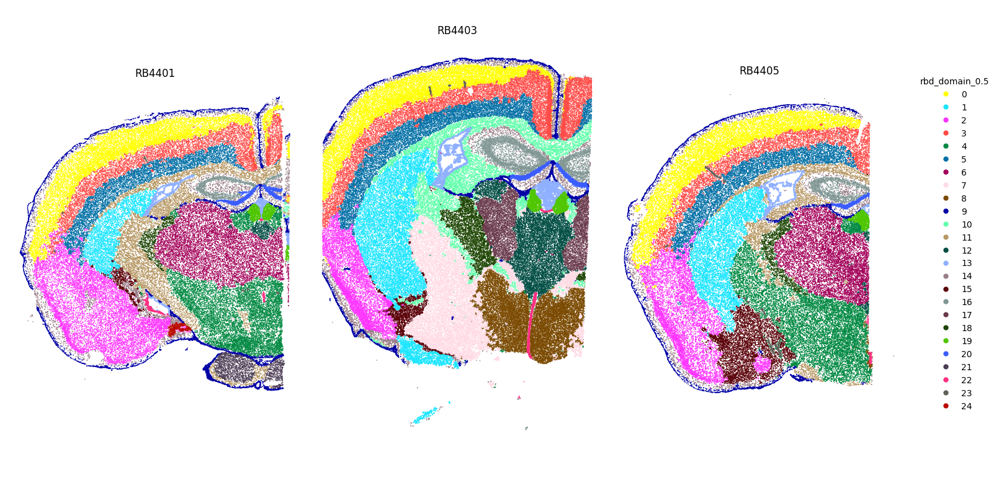

In [7]:
 plot_spatial_compact(adata, color='rbd_domain_0.5', groupby="sample_id",spot_size=20,
    cols=3,
    height=8,
    legend_col_width=1.0,)

/Users/christoffer/miniconda3/envs/sc_py312/lib/python3.12/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:342: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_lo], color=None, spot_size=spot_size,
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:349: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_hi], color=None, spot_size=spot_size,


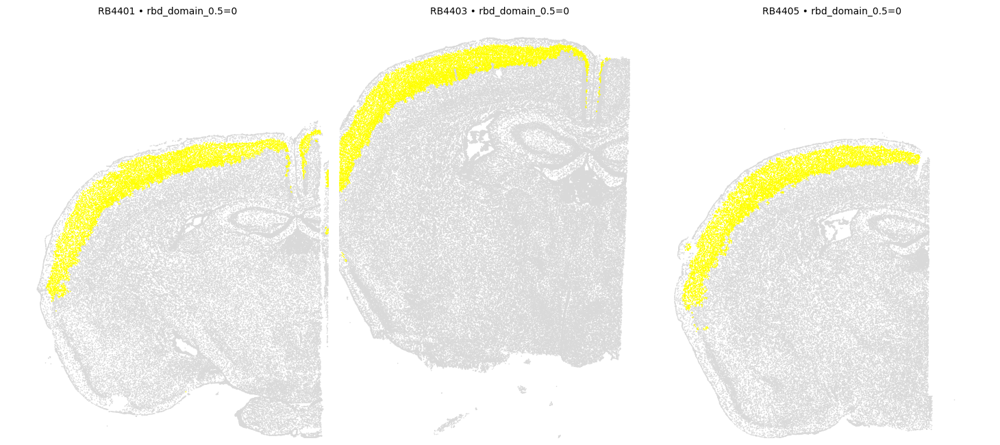

/Users/christoffer/miniconda3/envs/sc_py312/lib/python3.12/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:342: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_lo], color=None, spot_size=spot_size,
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:349: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_hi], color=None, spot_size=spot_size,


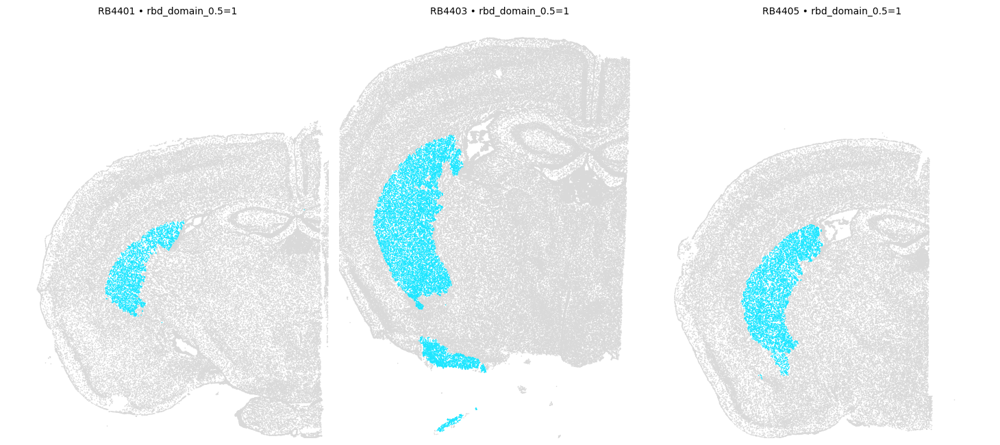

/Users/christoffer/miniconda3/envs/sc_py312/lib/python3.12/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:342: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_lo], color=None, spot_size=spot_size,
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:349: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_hi], color=None, spot_size=spot_size,


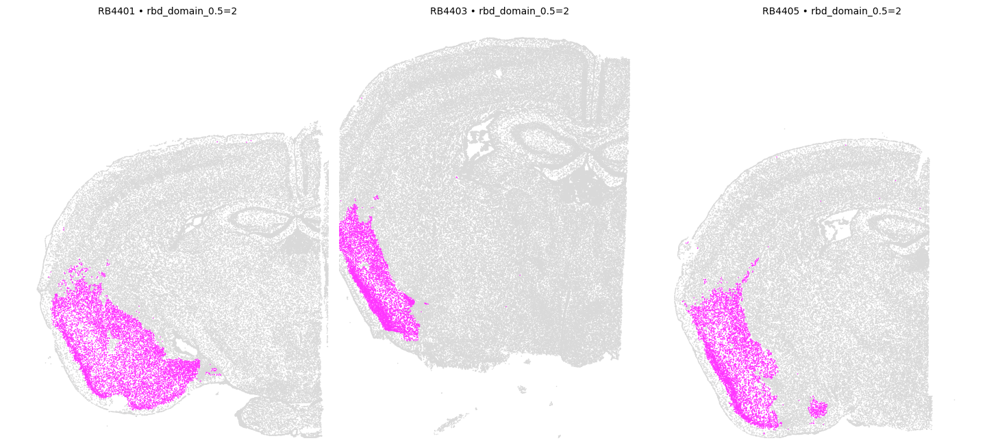

/Users/christoffer/miniconda3/envs/sc_py312/lib/python3.12/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:342: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_lo], color=None, spot_size=spot_size,
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:349: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_hi], color=None, spot_size=spot_size,


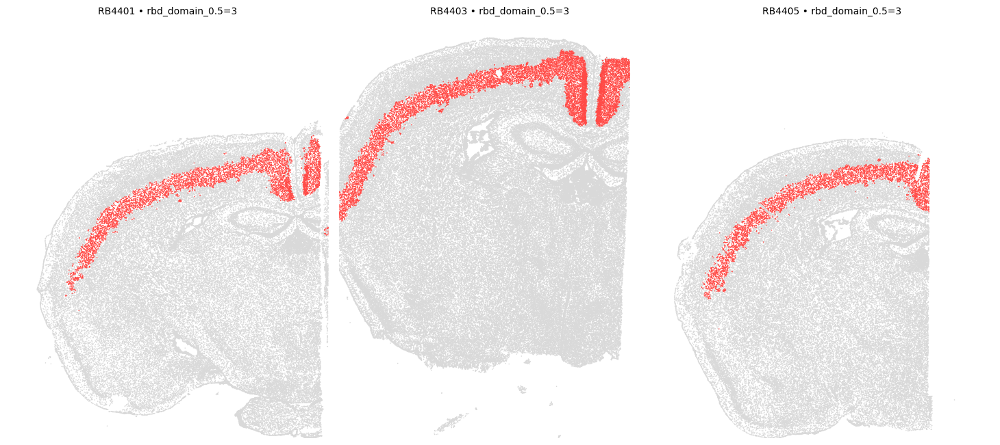

/Users/christoffer/miniconda3/envs/sc_py312/lib/python3.12/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:342: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_lo], color=None, spot_size=spot_size,
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:349: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_hi], color=None, spot_size=spot_size,


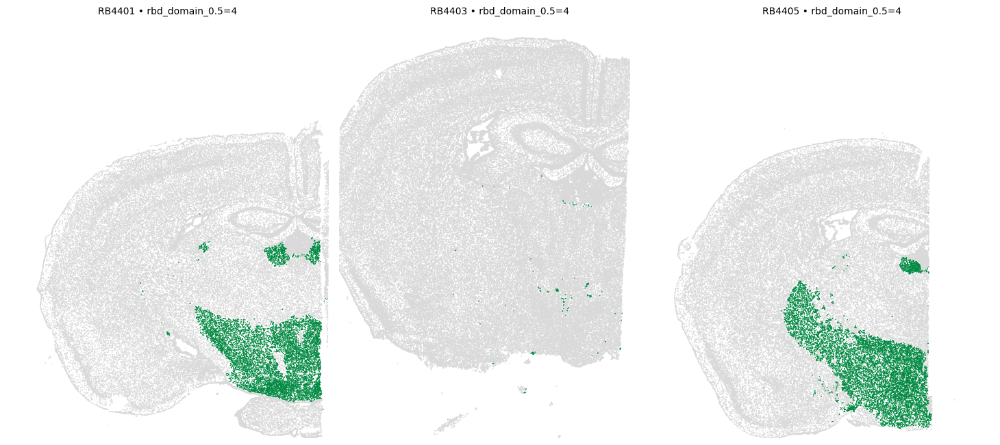

/Users/christoffer/miniconda3/envs/sc_py312/lib/python3.12/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:342: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_lo], color=None, spot_size=spot_size,
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:349: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_hi], color=None, spot_size=spot_size,


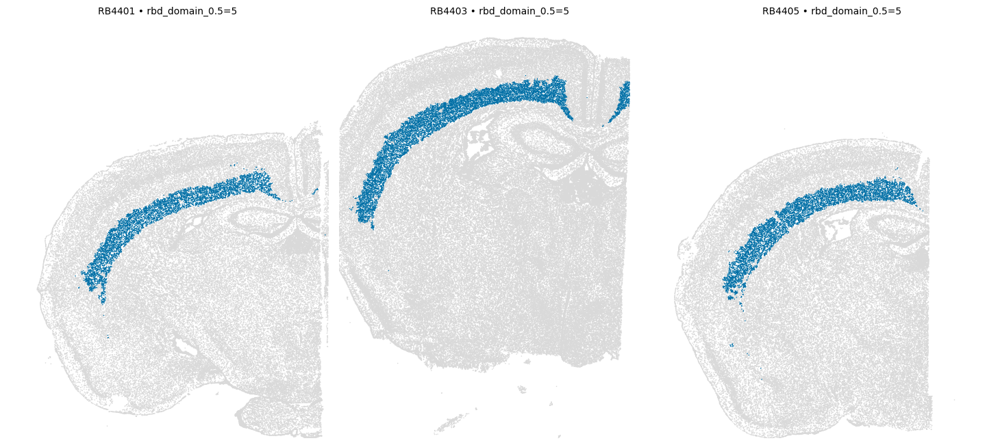

/Users/christoffer/miniconda3/envs/sc_py312/lib/python3.12/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:342: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_lo], color=None, spot_size=spot_size,
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:349: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_hi], color=None, spot_size=spot_size,


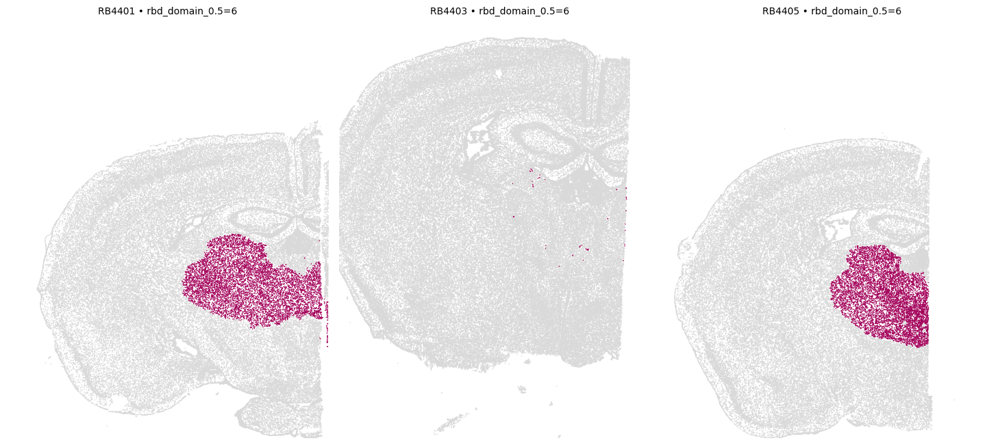

/Users/christoffer/miniconda3/envs/sc_py312/lib/python3.12/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:342: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_lo], color=None, spot_size=spot_size,
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:349: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_hi], color=None, spot_size=spot_size,


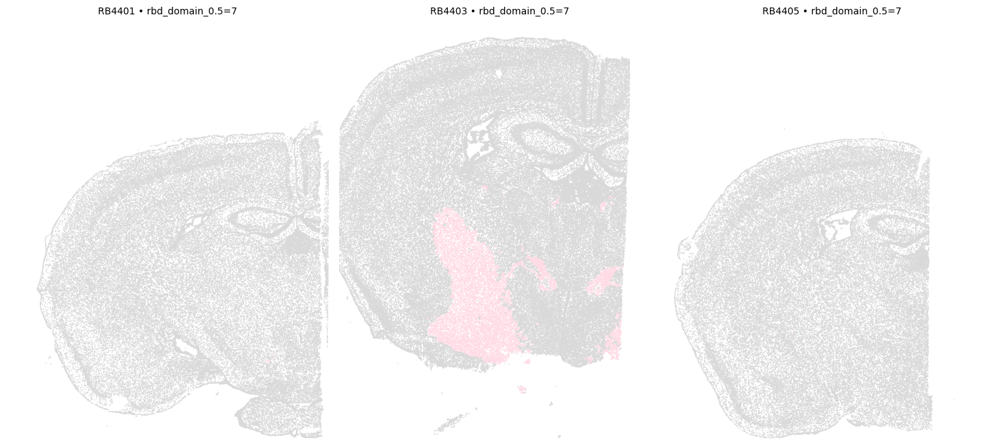

/Users/christoffer/miniconda3/envs/sc_py312/lib/python3.12/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:342: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_lo], color=None, spot_size=spot_size,
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:349: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_hi], color=None, spot_size=spot_size,


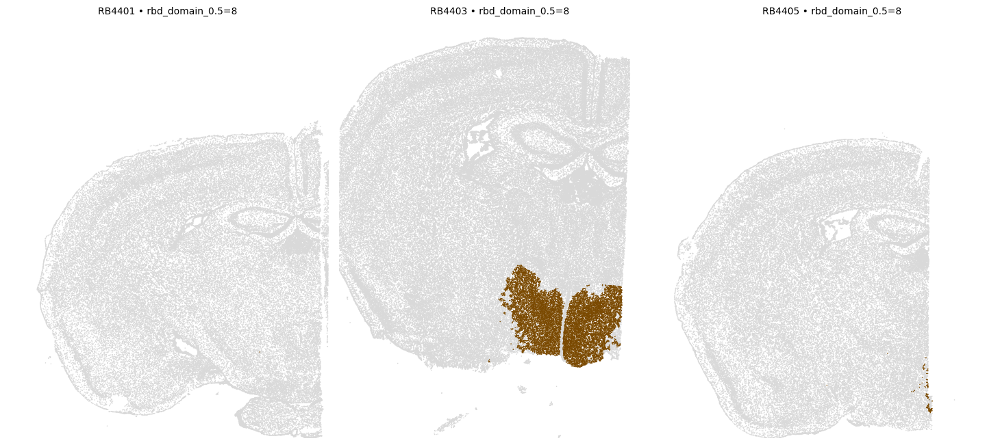

/Users/christoffer/miniconda3/envs/sc_py312/lib/python3.12/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:342: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_lo], color=None, spot_size=spot_size,
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:349: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_hi], color=None, spot_size=spot_size,


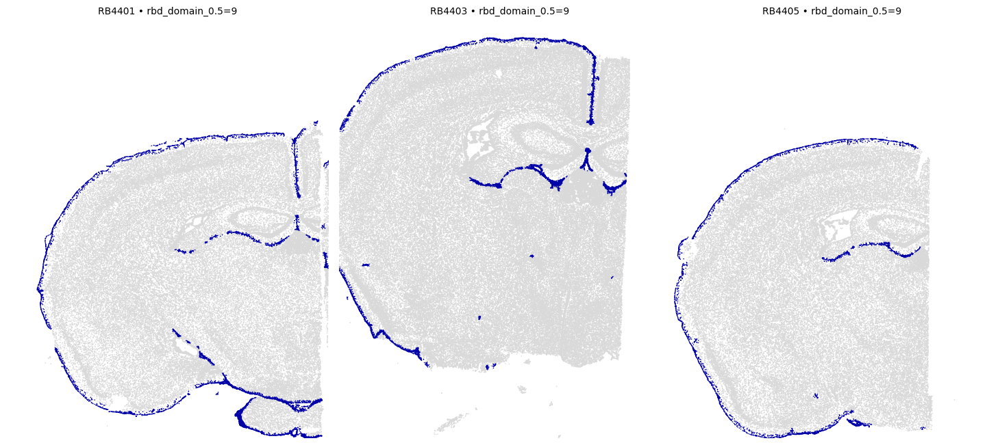

/Users/christoffer/miniconda3/envs/sc_py312/lib/python3.12/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:342: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_lo], color=None, spot_size=spot_size,
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:349: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_hi], color=None, spot_size=spot_size,


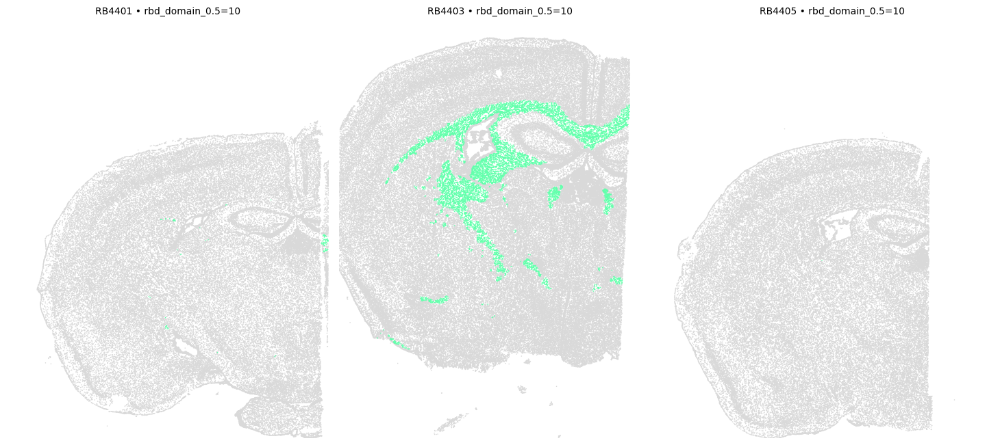

/Users/christoffer/miniconda3/envs/sc_py312/lib/python3.12/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:342: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_lo], color=None, spot_size=spot_size,
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:349: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_hi], color=None, spot_size=spot_size,


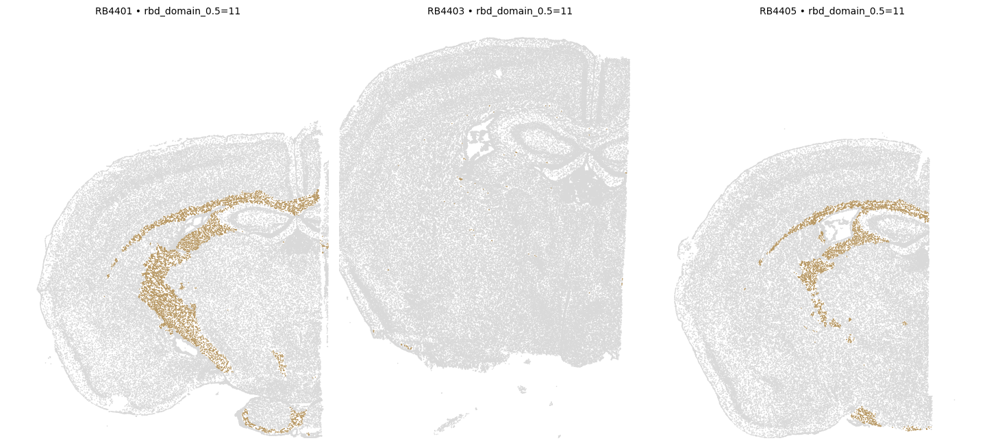

/Users/christoffer/miniconda3/envs/sc_py312/lib/python3.12/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:342: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_lo], color=None, spot_size=spot_size,
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:349: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_hi], color=None, spot_size=spot_size,


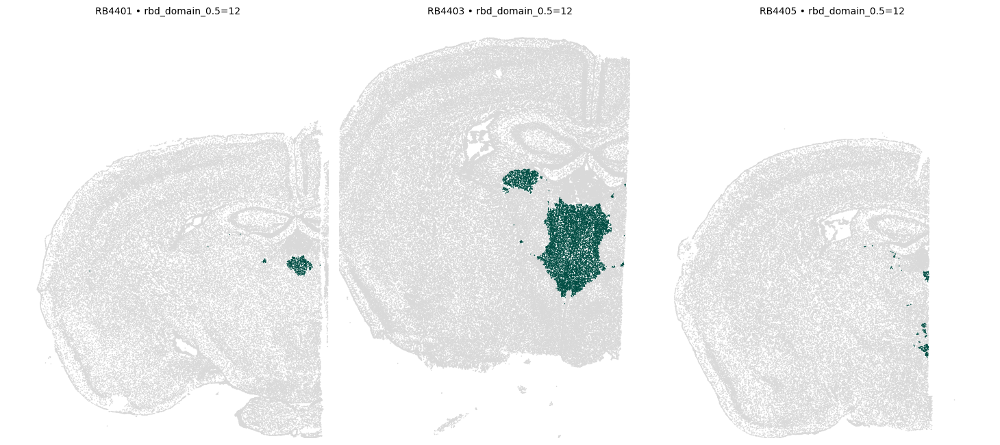

/Users/christoffer/miniconda3/envs/sc_py312/lib/python3.12/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:342: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_lo], color=None, spot_size=spot_size,
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:349: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_hi], color=None, spot_size=spot_size,


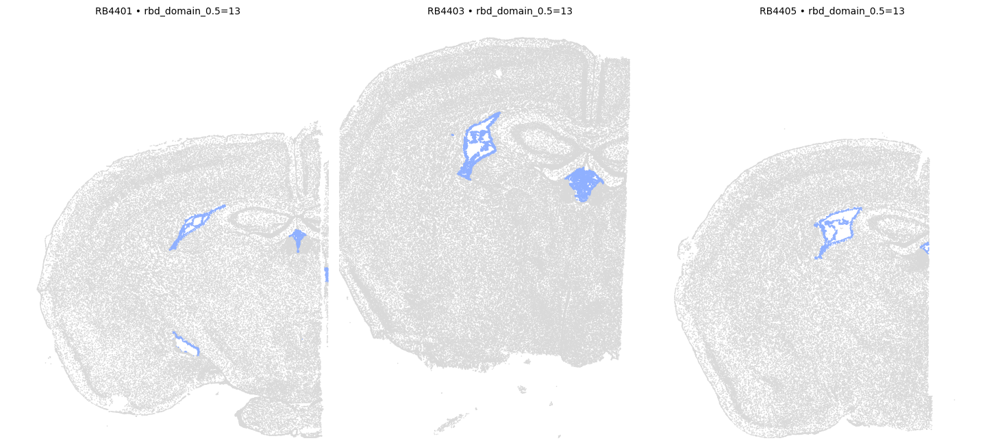

/Users/christoffer/miniconda3/envs/sc_py312/lib/python3.12/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:342: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_lo], color=None, spot_size=spot_size,
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:349: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_hi], color=None, spot_size=spot_size,


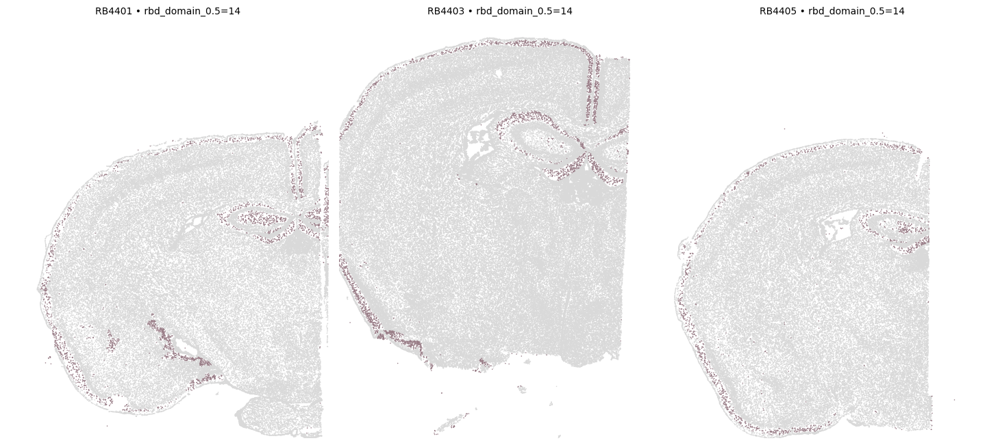

/Users/christoffer/miniconda3/envs/sc_py312/lib/python3.12/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:342: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_lo], color=None, spot_size=spot_size,
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:349: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_hi], color=None, spot_size=spot_size,


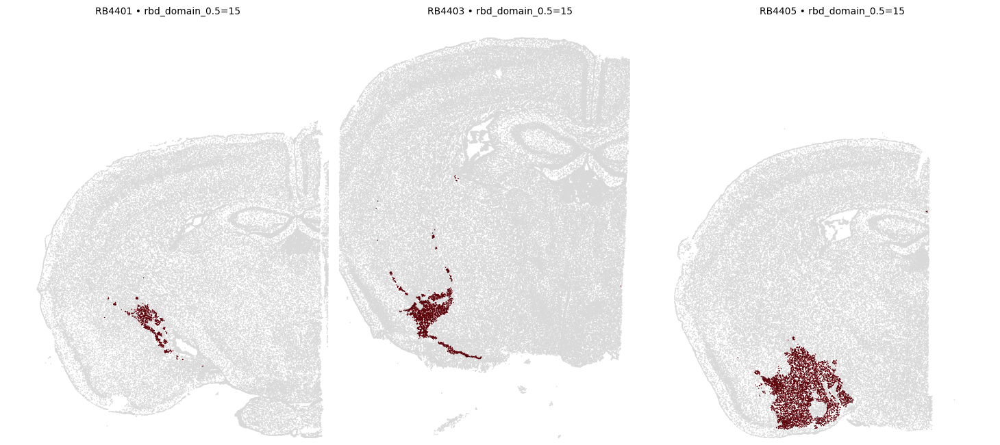

/Users/christoffer/miniconda3/envs/sc_py312/lib/python3.12/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:342: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_lo], color=None, spot_size=spot_size,
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:349: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_hi], color=None, spot_size=spot_size,


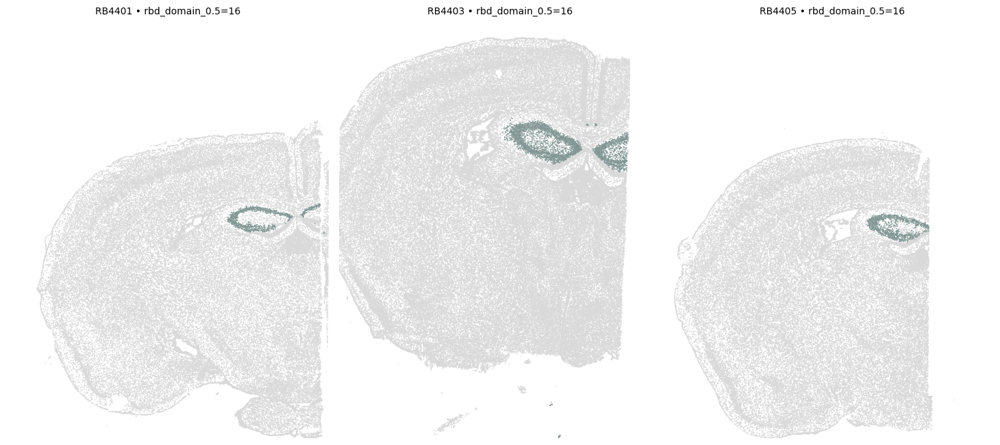

/Users/christoffer/miniconda3/envs/sc_py312/lib/python3.12/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:342: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_lo], color=None, spot_size=spot_size,
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:349: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_hi], color=None, spot_size=spot_size,


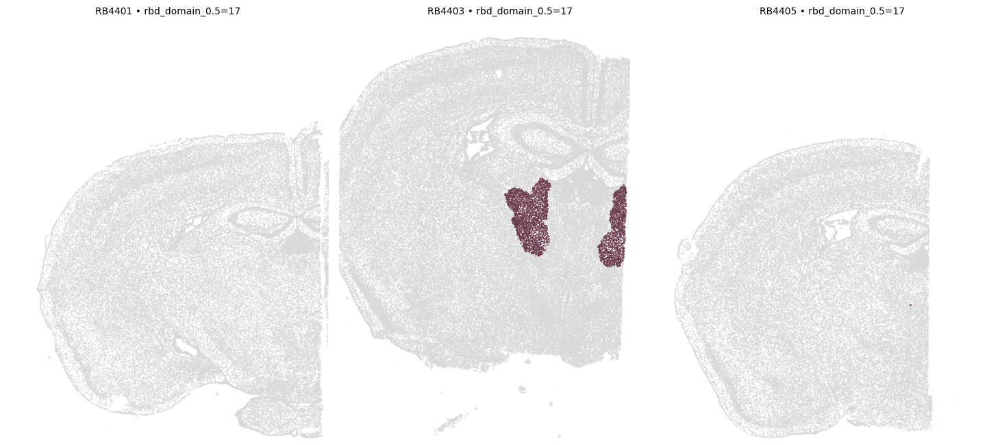

/Users/christoffer/miniconda3/envs/sc_py312/lib/python3.12/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:342: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_lo], color=None, spot_size=spot_size,
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:349: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_hi], color=None, spot_size=spot_size,


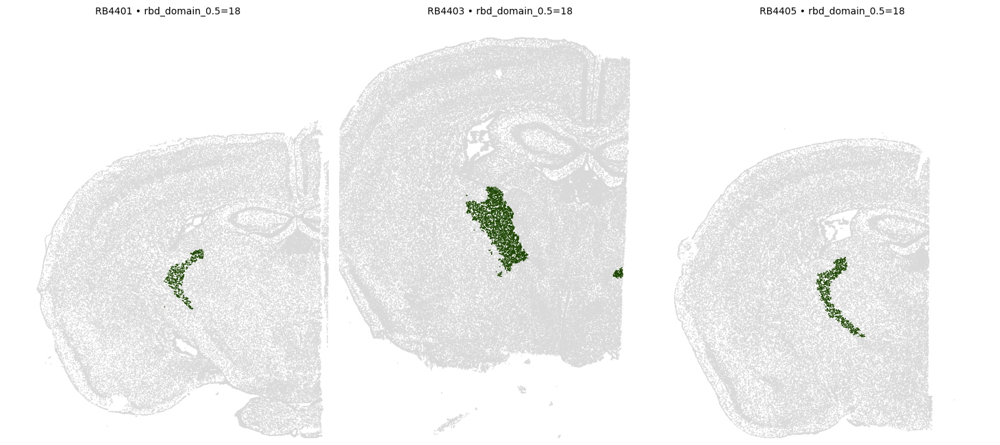

/Users/christoffer/miniconda3/envs/sc_py312/lib/python3.12/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:342: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_lo], color=None, spot_size=spot_size,
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:349: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_hi], color=None, spot_size=spot_size,


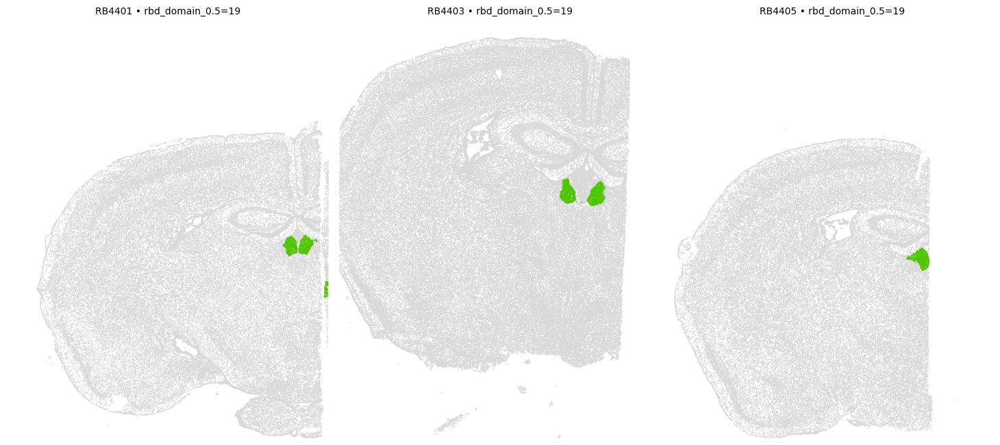

/Users/christoffer/miniconda3/envs/sc_py312/lib/python3.12/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:342: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_lo], color=None, spot_size=spot_size,
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:349: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_hi], color=None, spot_size=spot_size,


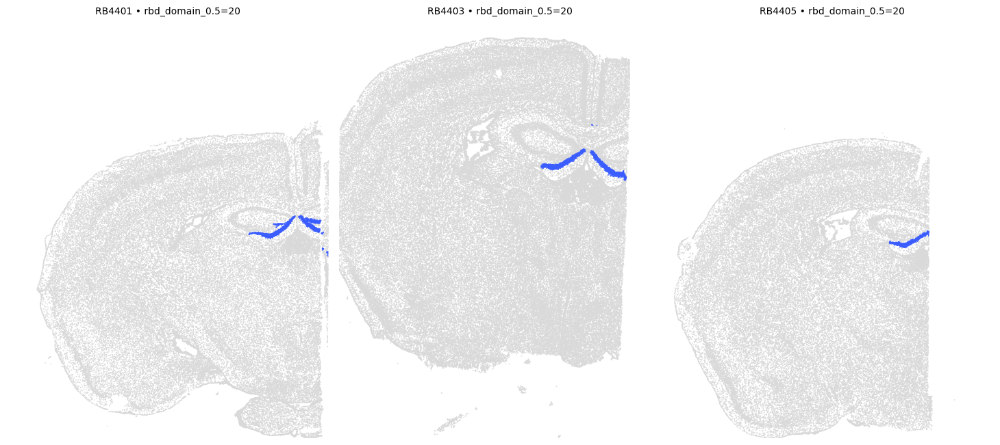

/Users/christoffer/miniconda3/envs/sc_py312/lib/python3.12/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:342: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_lo], color=None, spot_size=spot_size,
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:349: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_hi], color=None, spot_size=spot_size,


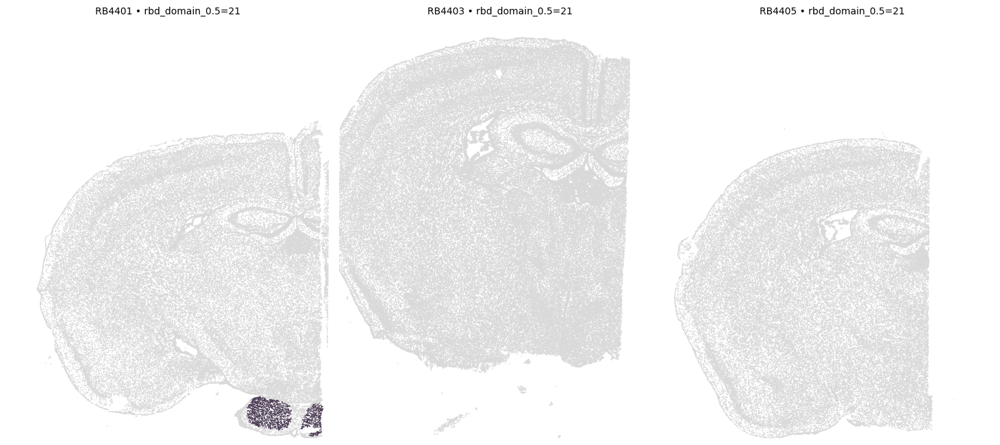

/Users/christoffer/miniconda3/envs/sc_py312/lib/python3.12/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:342: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_lo], color=None, spot_size=spot_size,
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:349: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_hi], color=None, spot_size=spot_size,


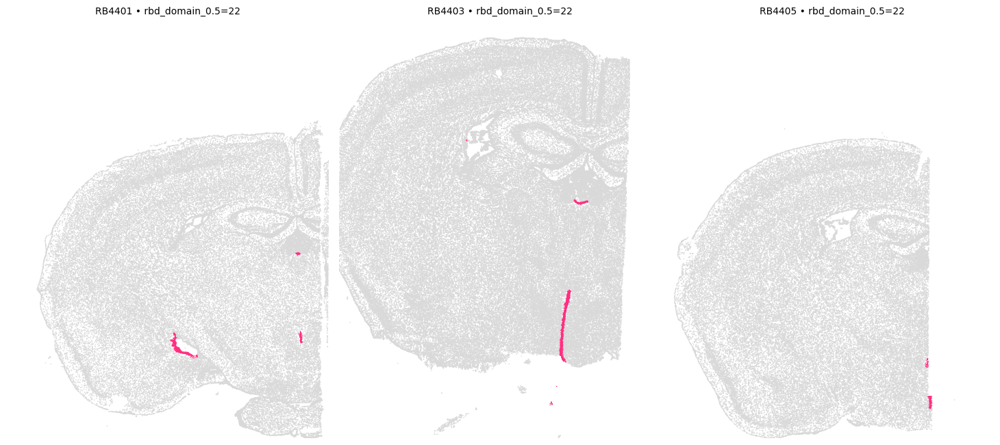

/Users/christoffer/miniconda3/envs/sc_py312/lib/python3.12/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:342: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_lo], color=None, spot_size=spot_size,
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:349: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_hi], color=None, spot_size=spot_size,


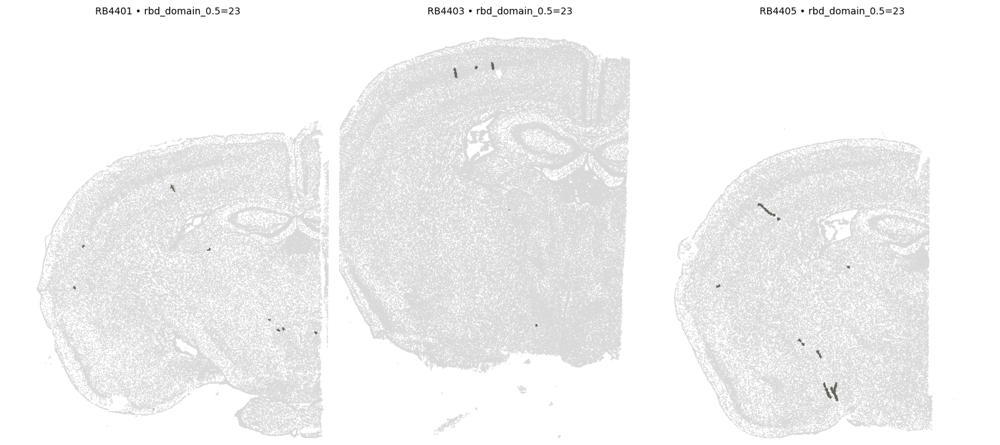

/Users/christoffer/miniconda3/envs/sc_py312/lib/python3.12/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:342: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_lo], color=None, spot_size=spot_size,
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:349: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad_sub[mask_hi], color=None, spot_size=spot_size,


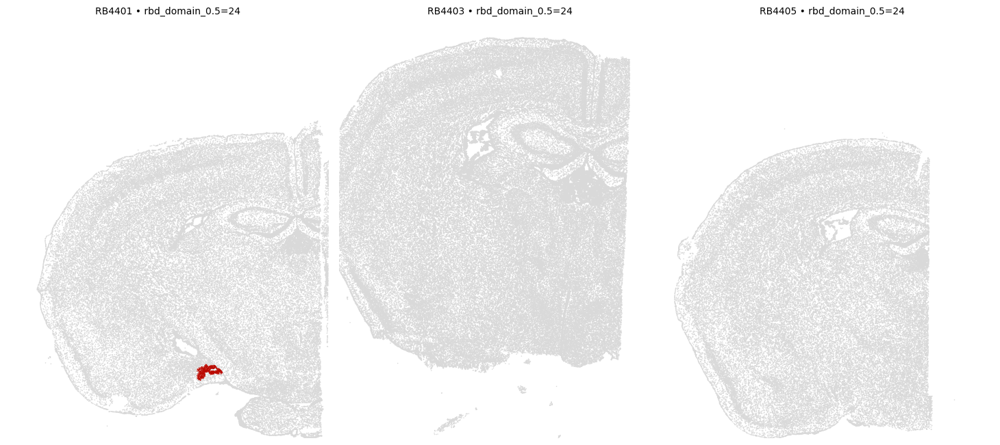

In [17]:
domain_key = "rbd_domain_0.5"

for cl in adata.obs[domain_key].astype("category").cat.categories:
    fig, _ = plot_spatial_highlight(
        adata, color=domain_key, highlight=cl,
        groupby="sample_id", spot_size=20, cols=3, height=7,
        flip_y=True, fix_limits=True
    )
    plt.show()
    #fig.savefig(os.path.join(outdir, f"{domain_key}_cluster_{cl}.png"),
    #            dpi=300, bbox_inches="tight")
    #plt.close(fig)

In [9]:
adata.obs['rbd_domain_0.5'].cat.categories

Index(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12',
       '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24'],
      dtype='object')

In [22]:
loose_mapping = {
    '0': 'Cortex I',
    '1': 'Caudoputamen',
    '2': 'Olfactory areas',
    '3': 'Cortex II',
    '4': 'Hypothalamus I',
    '5': 'Cortex III',
    '6': 'Thalamus I',
    '7': 'Striatum',
    '8': 'Hypothalamus II',
    '9': 'Meninges',
    '10': 'Fiber tracts (corpus and internal capsule)',
    '11': 'Fiber tracts (corpus and internal capsule)',
    '12': 'Thalamus II',
    '13': 'Ventricular systems',
    '14': 'Meningeal–parenchymal border domain',
    '15': 'Palladium',
    '16': 'Hippocampal formation',
    '17': 'Thalamus III',
    '18': 'Thalamus IV',
    '19': 'Medial habenula',
    '20': 'Dentate gyrus',
    '21': 'Unknown',
    '22': 'Ventricular systems',
    '23': 'Vasculature',
    '24': 'Vasculature'
}


In [23]:
adata.obs['rbd_annotation'] = adata.obs['rbd_domain_0.5'].map(loose_mapping)

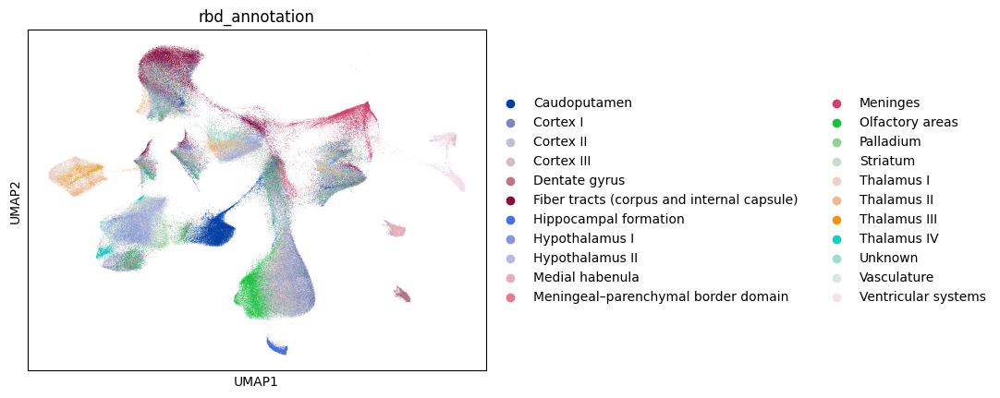

In [32]:
sc.pl.umap(adata, color = 'rbd_annotation')

In [31]:
#del adata.uns['rbd_annotation_colors']

/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:68: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:68: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/1441284356.py:68: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


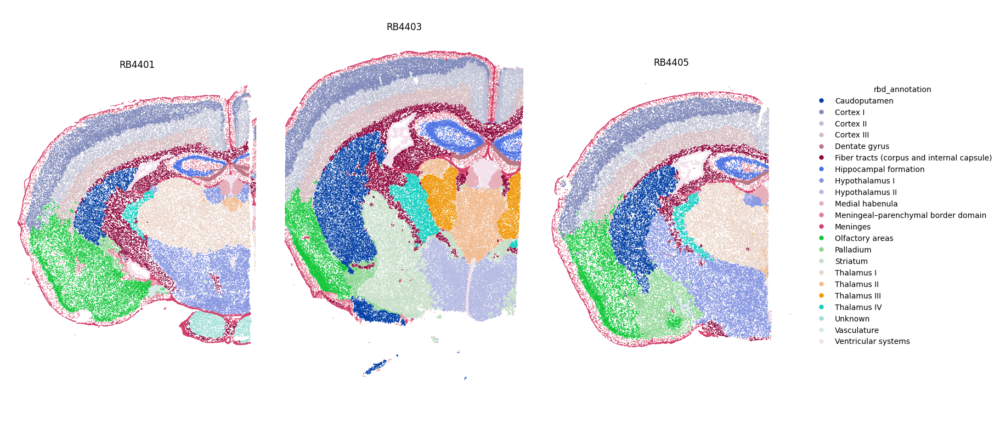

In [33]:
 plot_spatial_compact(adata, color='rbd_annotation', groupby="sample_id",spot_size=20,
    cols=3,
    height=8,
    legend_col_width=1.0,)

In [109]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def compartment_composition(
    adata,
    compartment,
    anno_key="rbd_annotation",
    groupby="cell_class",
    sort=True
) -> pd.DataFrame:
    """
    Return counts and percentages of `groupby` within one compartment.

    Parameters
    ----------
    adata : AnnData
    compartment : str                      # e.g. 'Meningeal–parenchymal border domain'
    anno_key : str                         # column in .obs that holds the compartment labels
    groupby : str                          # column in .obs to summarize (e.g. cell_class)
    sort : bool                            # sort by descending percentage

    Returns
    -------
    DataFrame with columns: ['count', 'percent'] indexed by group
    """
    mask = (adata.obs[anno_key] == compartment)
    sub = adata.obs.loc[mask, groupby].value_counts()
    total = int(sub.sum())
    df = pd.DataFrame({"count": sub.astype(int)})
    df["percent"] = df["count"] / total * 100.0
    if sort:
        df = df.sort_values("percent", ascending=False)
    df.attrs["total"] = total
    df.attrs["compartment"] = compartment
    df.attrs["groupby"] = groupby
    return df


def plot_compartment_bar(df: pd.DataFrame, top_n=None, title=None, ax=None):
    """
    Horizontal barplot of composition (percent). Accepts the DataFrame returned by `compartment_composition`.
    """
    if top_n is not None:
        d = df.head(top_n)
    else:
        d = df

    if ax is None:
        h = max(3, 0.35 * len(d))
        fig, ax = plt.subplots(figsize=(7, h))

    ax.barh(d.index[::-1], d["percent"][::-1])
    for i, (y, v) in enumerate(zip(d.index[::-1], d["percent"][::-1])):
        ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=9)

    comp = df.attrs.get("compartment", "")
    groupby = df.attrs.get("groupby", "")
    total = df.attrs.get("total", None)
    ttl = title or f"{comp} • {groupby} composition"
    if total is not None:
        ttl += f"  (n={total})"

    ax.set_title(ttl)
    ax.set_xlabel("Percent of cells")
    ax.set_ylabel(groupby)
    ax.set_xlim(0, max(100, float(d["percent"].max()) + 5))
    ax.spines[['top','right']].set_visible(False)
    plt.tight_layout()
    return ax


def compare_compartments_heatmap(
    adata,
    compartments,
    anno_key="rbd_annotation",
    groupby="cell_class",
    top_k=None,
    figsize=(10, 6),
    cmap="viridis"
):
    """
    Heatmap of percentages across multiple compartments.
    If `top_k` is set, uses the globally most abundant K classes across all chosen compartments.
    """
    mats = []
    for comp in compartments:
        df = compartment_composition(adata, comp, anno_key=anno_key, groupby=groupby, sort=False)
        mats.append(df["percent"])

    M = pd.concat(mats, axis=1)
    M.columns = list(compartments)
    M = M.fillna(0.0)

    if top_k is not None and top_k < M.shape[0]:
        order = M.sum(1).sort_values(ascending=False).index[:top_k]
        M = M.loc[order]

    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(M.values, aspect="auto", cmap=cmap)
    ax.set_xticks(range(M.shape[1]))
    ax.set_xticklabels(M.columns, rotation=0)
    ax.set_yticks(range(M.shape[0]))
    ax.set_yticklabels(M.index)
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label("% within compartment")
    ax.set_title(f"{groupby} composition across compartments")
    plt.tight_layout()
    return ax, M

/var/folders/pm/2253tbm54v36j0l7lhshq73r0000gn/T/ipykernel_77638/3502475362.py:51: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize=(7, h))


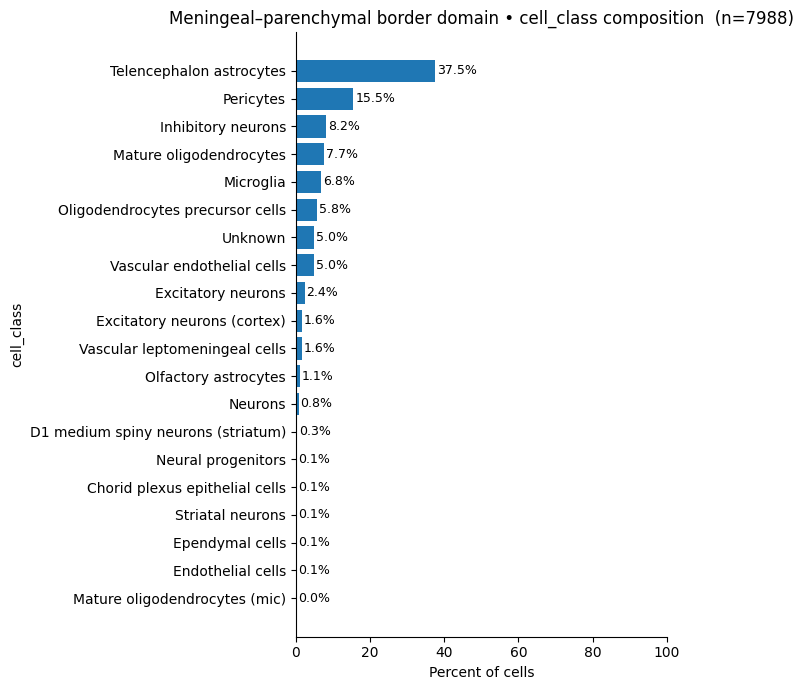

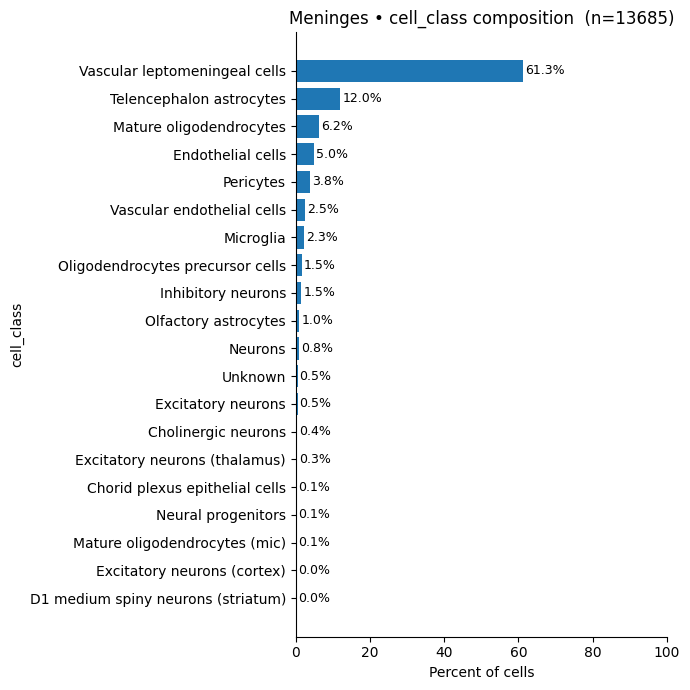

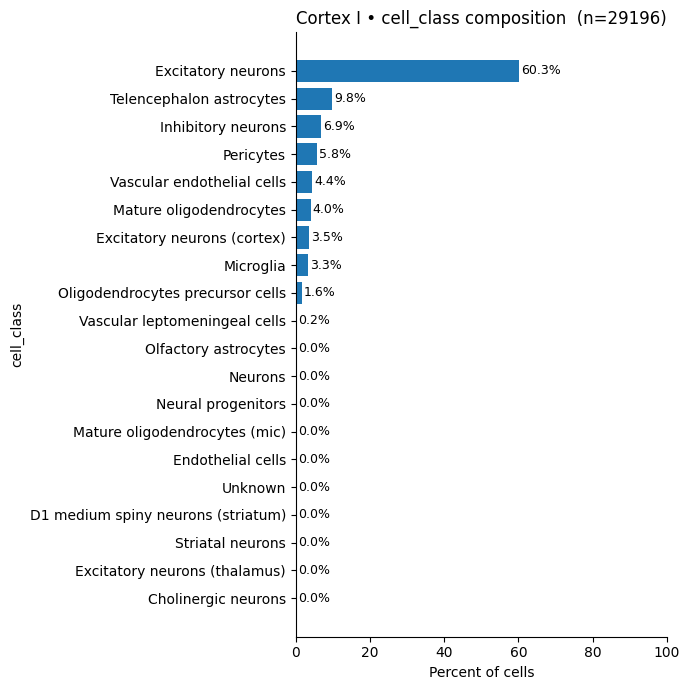

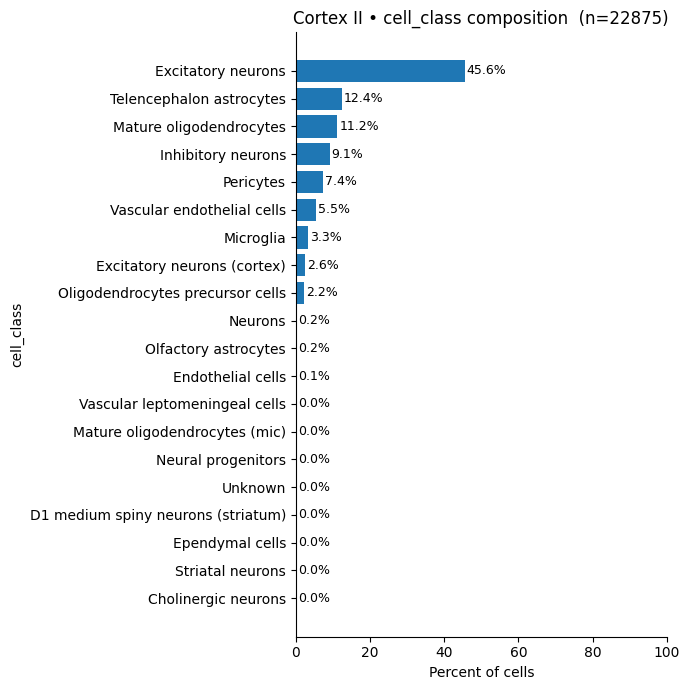

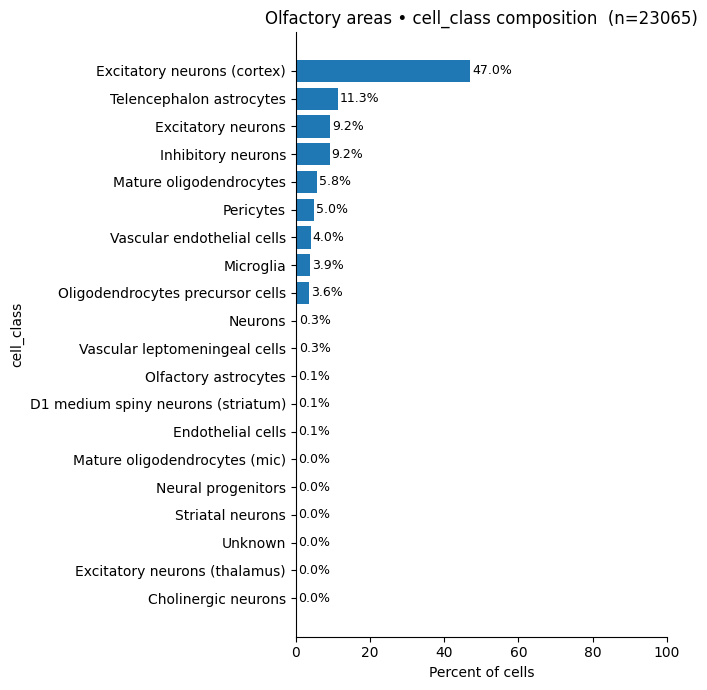

...

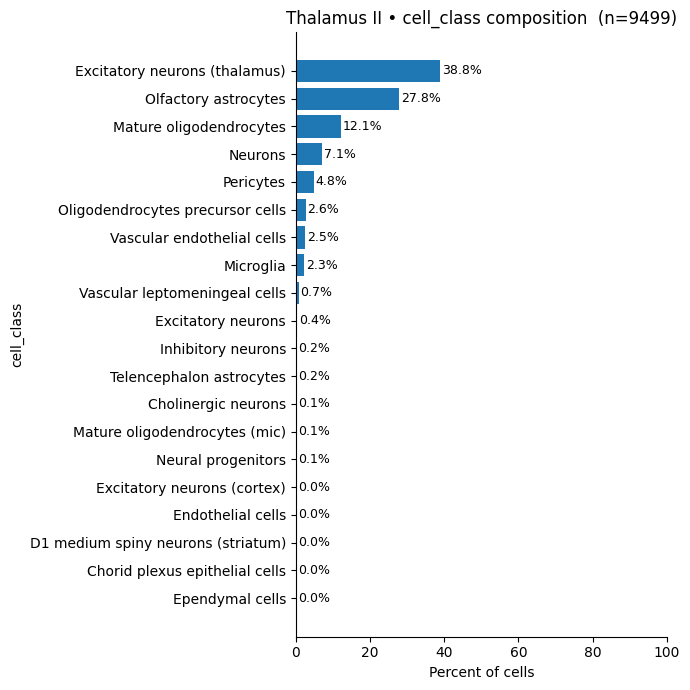

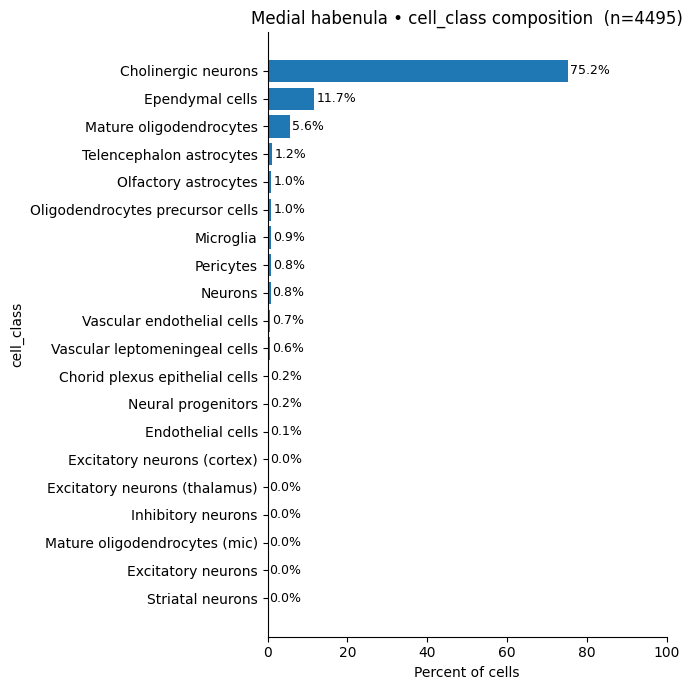

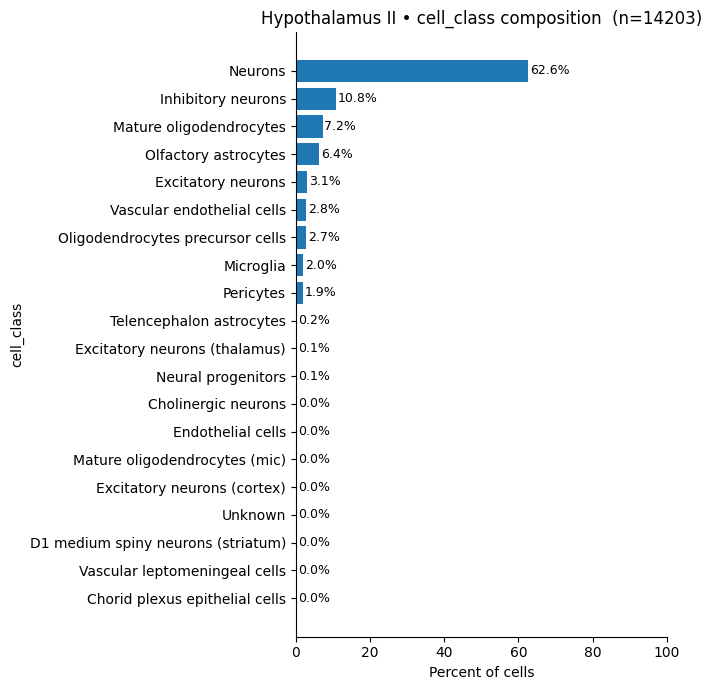

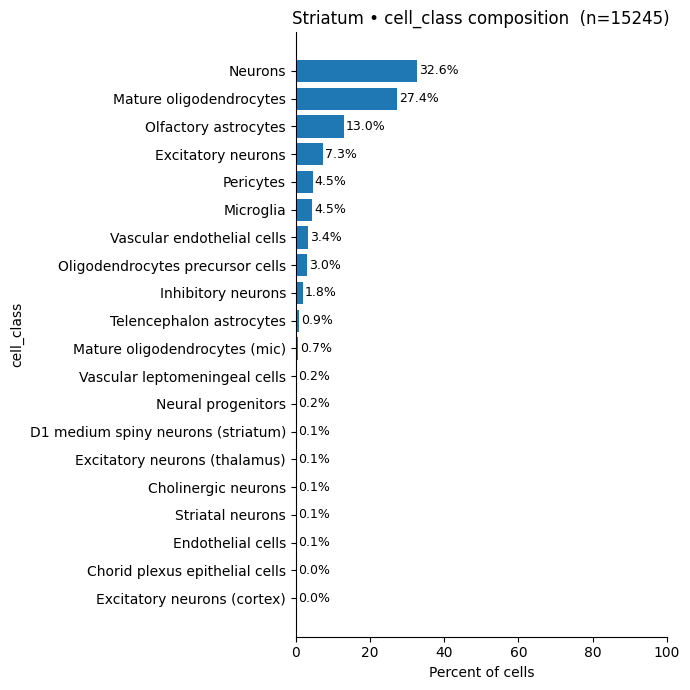

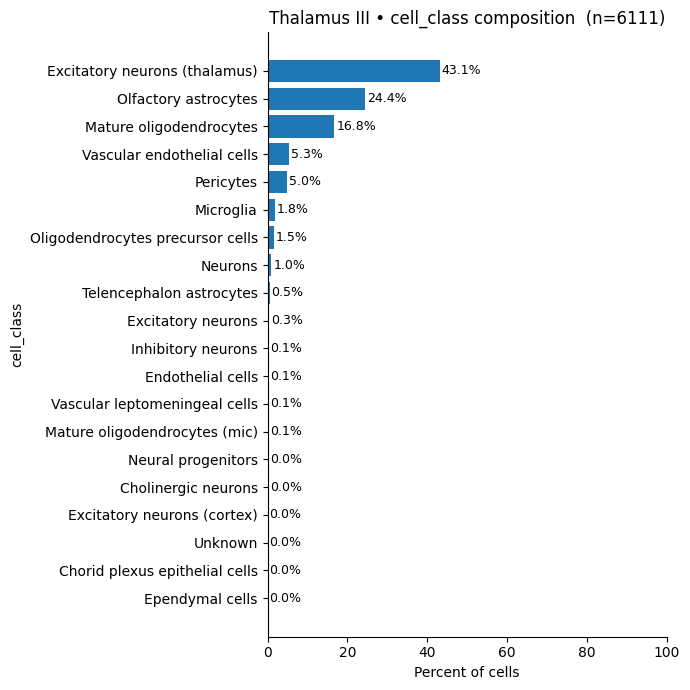

In [119]:
for domain in adata.obs.rbd_annotation.unique():
    df_border = compartment_composition(adata, domain, anno_key="rbd_annotation", groupby="cell_class")
    plot_compartment_bar(df_border, top_n=20);   # plot top 20 classes

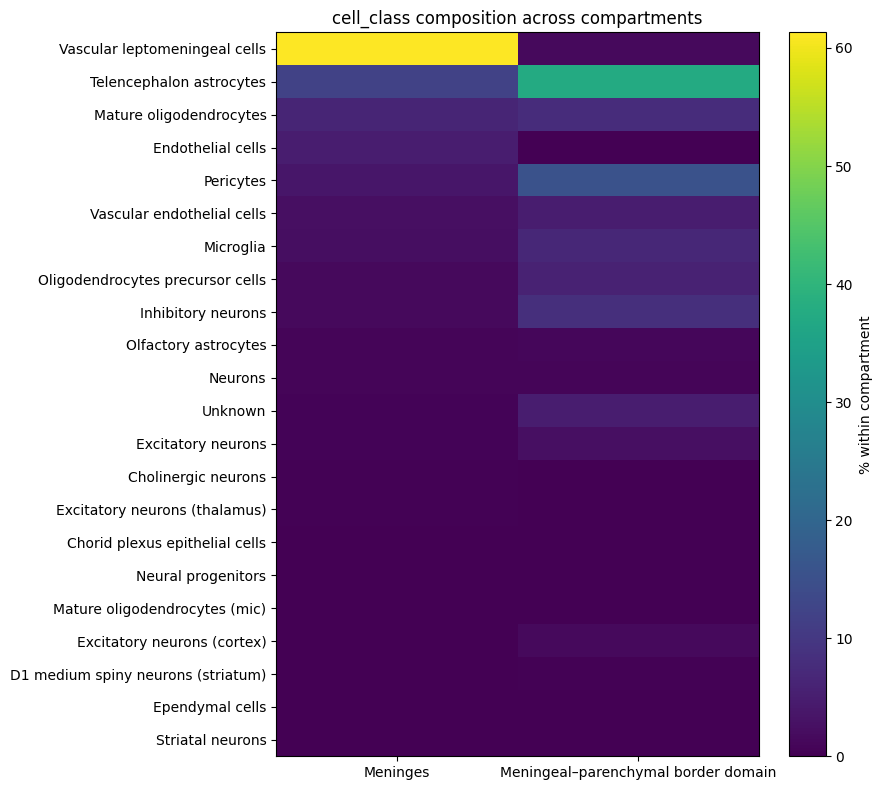

In [111]:
# 2) Compare compartments side-by-side (heatmap)
ax, mat = compare_compartments_heatmap(
    adata,
    compartments=["Meninges", "Meningeal–parenchymal border domain"],
    anno_key="rbd_annotation",
    groupby="cell_class",
    top_k=25,                  # show top 25 cell classes overall
    figsize=(9, 8)
)

In [179]:
adata[adata.obs.cell_class == 'Microglia'].obs.rbd_annotation.value_counts()

rbd_annotation
Hypothalamus I                                1074
Cortex I                                       973
Olfactory areas                                902
Caudoputamen                                   853
Thalamus I                                     797
Cortex II                                      750
Fiber tracts (corpus and internal capsule)     700
Striatum                                       686
Cortex III                                     579
Meningeal–parenchymal border domain            546
Meninges                                       313
Hypothalamus II                                280
Palladium                                      252
Thalamus II                                    220
Thalamus IV                                    178
Hippocampal formation                          168
Thalamus III                                   108
Ventricular systems                             83
Unknown                                         47
Medial habenula 

In [126]:
genes = [
    # 🔥 Oxidative stress defenses
    "Mt2", "Gstp1", "Sqstm1", "Nfe2l1",

    # ⚡ Mitochondrial and ER stress signaling
    "Atf4", "Jun", "Atf5", "Hspa5", "Hspd1", "Hspa9",

    # 🧩 Mitokine-like secretome
    "Gdf15", "Adm", "Cst7", "Igfbp3", "Serpina3n",

    # 🛡️ Antigen presentation and immune visibility
    "B2m", "H2-D1", "H2-K1", "Ctss",

    # 🚚 Transport and myelin support disruption
    "Kif5a", "Kif5b", "Dync1li1", "Itgb1", "Mpzl1",

    # 🌟 Reactivity and glial crosstalk
    "Ndrg2", "Gfap", "S100a1", "Calb2",

    # 📣 Inflammatory mediators
    "Nmu", "Ccl3"
]

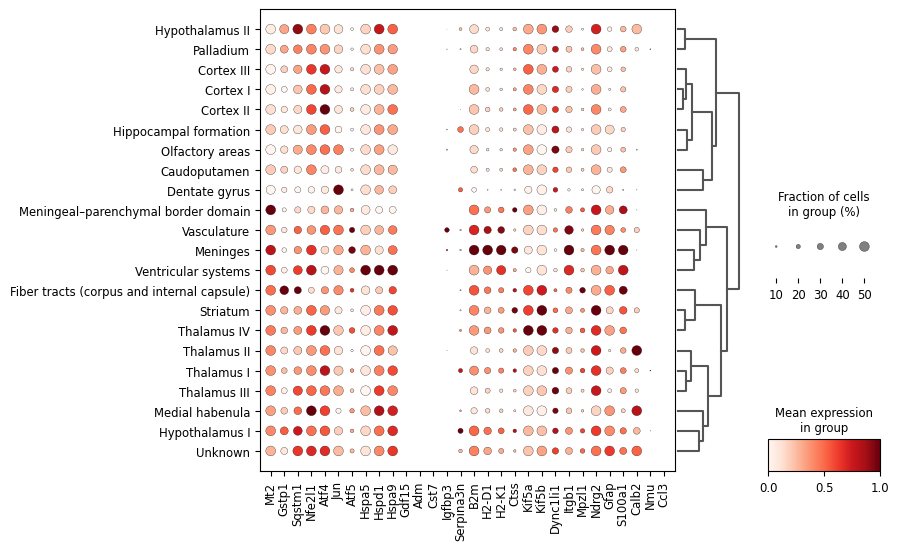

In [160]:
sc.pl.dotplot(
        adata,
        var_names=genes,
        groupby="rbd_annotation",
        standard_scale="var",
        dot_max=0.5,
        dot_min=0.05,
        color_map="Reds",
        dendrogram=True,
        figsize=(8, 6)
    )

In [164]:
import numpy as np
import pandas as pd
import scipy.sparse as sp

def extract_dotplot_data_from_adata(
    adata,
    genes,
    groupby="rbd_annotation",
    layer=None,               # e.g. "log1p", else uses .X
    thresh=0.0,               # expression > thresh counts as "expressing"
    standard_scale=None,      # None or "var" (min–max per gene)
    return_tidy=True,
    to_csv_prefix=None        # e.g. "dotplot"; will write 2 CSVs if set
):
    """
    Compute per-group mean expression and fraction expressing for selected genes.
    Returns:
      {"mean": DataFrame[genes x groups],
       "frac": DataFrame[genes x groups],
       "mean_scaled": (optional) DataFrame if standard_scale="var",
       "tidy": (optional) long-form DataFrame}
    """
    # 1) restrict to genes present
    present = [g for g in genes if g in adata.var_names]
    missing = sorted(set(genes) - set(present))
    if missing:
        print(f"[warn] {len(missing)} genes not found and will be skipped: {missing}")

    if not present:
        raise ValueError("None of the requested genes are in adata.var_names.")

    groups = adata.obs[groupby].astype("category")
    group_names = list(groups.cat.categories)

    # 2) choose matrix
    X_all = adata.layers[layer] if layer is not None else adata.X
    is_sparse = sp.issparse(X_all)

    # 3) build result holders
    mean_mat = np.zeros((len(present), len(group_names)), dtype=float)
    frac_mat = np.zeros((len(present), len(group_names)), dtype=float)

    # 4) compute per group
    for j, g in enumerate(group_names):
        mask = (groups.values == g)
        if mask.sum() == 0:
            continue
        # slice rows by group, columns by genes
        idx_cols = adata.var_names.get_indexer(present)  # integer indices
        Xg = X_all[mask][:, idx_cols]

        # means
        if is_sparse:
            # sparse mean keeps shape (1, n) — convert to 1D
            means = np.asarray(Xg.mean(axis=0)).ravel()
            # fraction expressing
            frac  = np.asarray((Xg > thresh).mean(axis=0)).ravel()
        else:
            means = Xg.mean(axis=0)
            frac  = (Xg > thresh).mean(axis=0)

        mean_mat[:, j] = means
        frac_mat[:, j] = frac

    mean_df = pd.DataFrame(mean_mat, index=present, columns=group_names)
    frac_df = pd.DataFrame(frac_mat, index=present, columns=group_names)

    out = {"mean": mean_df, "frac": frac_df}

    # 5) optional standard_scale="var" → min–max per gene across groups
    if standard_scale == "var":
        mm = (mean_df.T - mean_df.min(axis=1)) / (mean_df.max(axis=1) - mean_df.min(axis=1) + 1e-12)
        mean_scaled = mm.T
        out["mean_scaled"] = mean_scaled

    # 6) optional tidy long format
    # 6) optional tidy long format  ✅ fixed merge keys
    if return_tidy:
        base = out.get("mean_scaled", mean_df)  # what you'd map to color
        left = (
            base.reset_index()                       # has columns: ["gene", groups...]
                .rename(columns={"index": "gene"})
                .melt(id_vars="gene", var_name=groupby, value_name="mean_scaled_or_mean")
        )
        right = (
            frac_df.reset_index()
                   .rename(columns={"index": "gene"})
                   .melt(id_vars="gene", var_name=groupby, value_name="frac")
        )
        tidy = left.merge(right, on=["gene", groupby], how="left")
        out["tidy"] = tidy

    # 7) optional CSVs
    if to_csv_prefix:
        mean_df.to_csv(f"{to_csv_prefix}.mean.csv")
        frac_df.to_csv(f"{to_csv_prefix}.frac.csv")
        if "mean_scaled" in out:
            out["mean_scaled"].to_csv(f"{to_csv_prefix}.mean_scaled.csv")
        if "tidy" in out:
            out["tidy"].to_csv(f"{to_csv_prefix}.tidy.csv", index=False)

    return out

In [165]:
genes = ["Mt2","Gstp1","Sqstm1","Nfe2l1","Atf4","Jun","Atf5","Hspa5","Hspd1","Hspa9",
         "Gdf15","Adm","Cst7","Igfbp3","Serpina3n","B2m","H2-D1","H2-K1","Ctss",
         "Kif5a","Kif5b","Dync1li1","Itgb1","Mpzl1","Ndrg2","Gfap","S100a1","Calb2","Nmu","Ccl3"]

out = extract_dotplot_data_from_adata(
    adata,
    genes=genes,
    groupby="rbd_annotation",
    layer=None,                 # or a specific layer name
    thresh=0.0,
    standard_scale="var",       # matches your dotplot
    return_tidy=True,
    #to_csv_prefix="dotplot_values"
)

# Access:
# out["mean"]         -> raw mean expression (genes x groups)
# out["frac"]         -> fraction expressing (genes x groups)
# out["mean_scaled"]  -> min–max per gene across groups (if requested)
# out["tidy"]         -> long-form table ready for seaborn/matplotlib

In [172]:
out['tidy'].to_csv('../results/tidy_region_sub_set_exp.csv')

In [175]:
top_genes = (
    out['tidy'].sort_values(["rbd_annotation", "mean_scaled_or_mean"], ascending=[True, False])
      .groupby("rbd_annotation")
      .head(3)[["rbd_annotation", "gene", "mean_scaled_or_mean"]]
)
top_genes.head(50)

,rbd_annotation,gene,mean_scaled_or_mean
21,Caudoputamen,Dync1li1,0.602838
18,Caudoputamen,Ctss,0.466885
3,Caudoputamen,Nfe2l1,0.414876
34,Cortex I,Atf4,0.820791
51,Cortex I,Dync1li1,0.685435
33,Cortex I,Nfe2l1,0.500893
64,Cortex II,Atf4,0.998285
81,Cortex II,Dync1li1,0.663962
63,Cortex II,Nfe2l1,0.597369
94,Cortex III,Atf4,0.768516


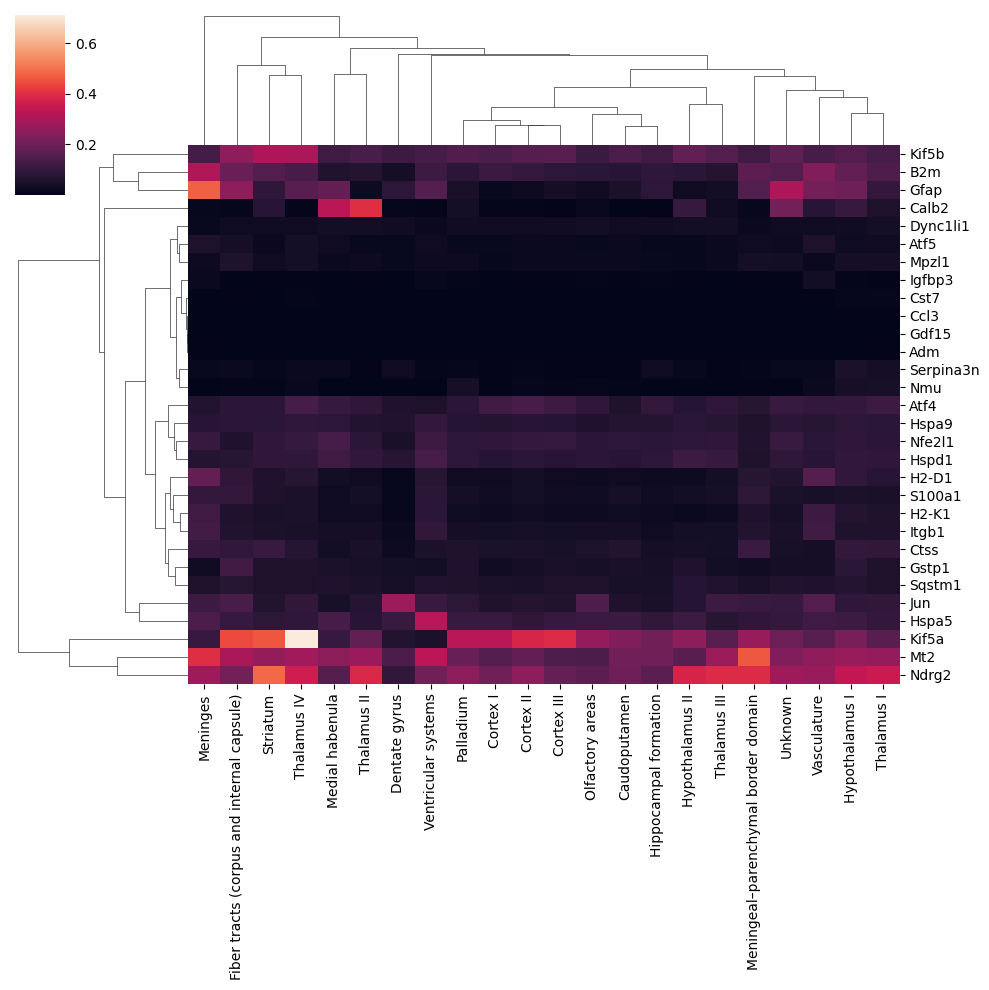

In [169]:
import seaborn as sns
sns.clustermap(out['mean'])

In [130]:
import warnings
warnings.filterwarnings("ignore")

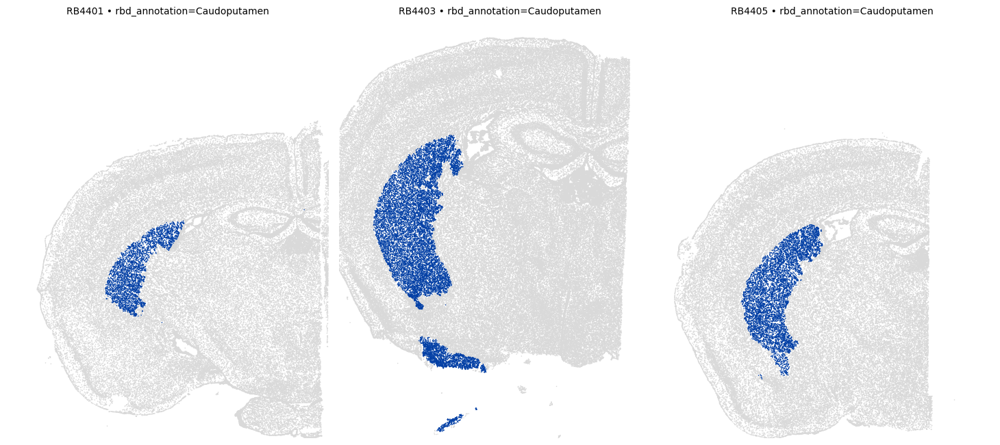

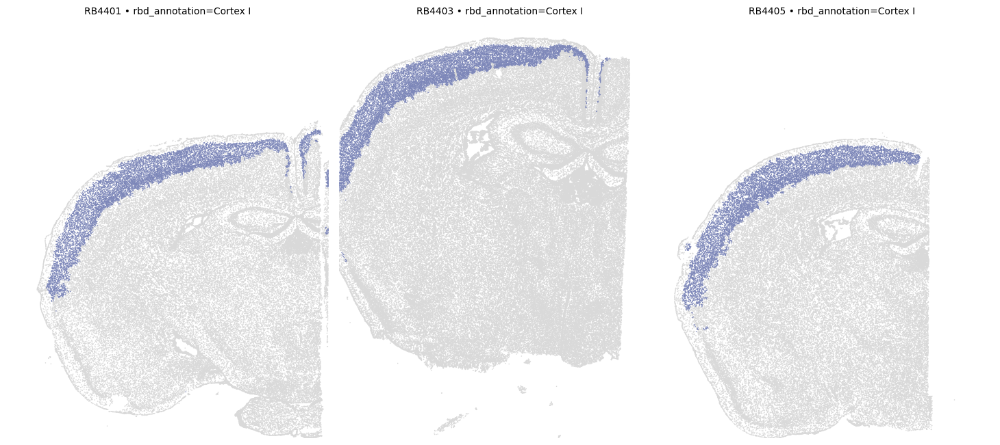

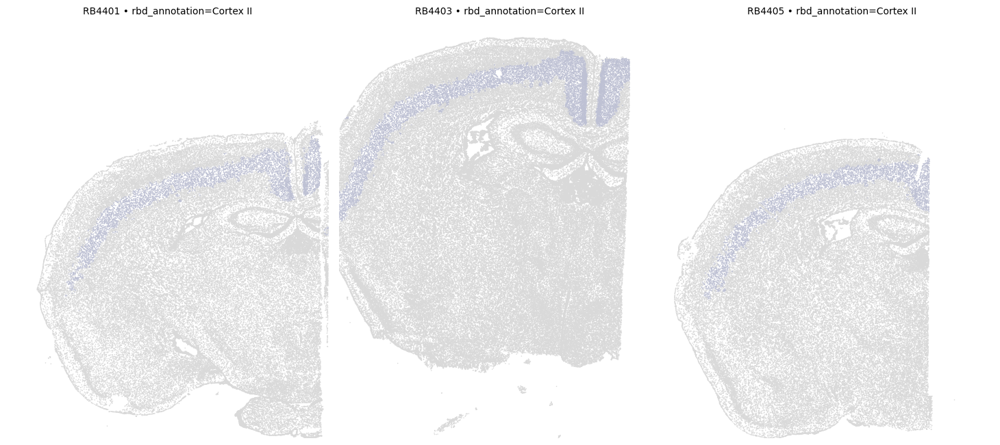

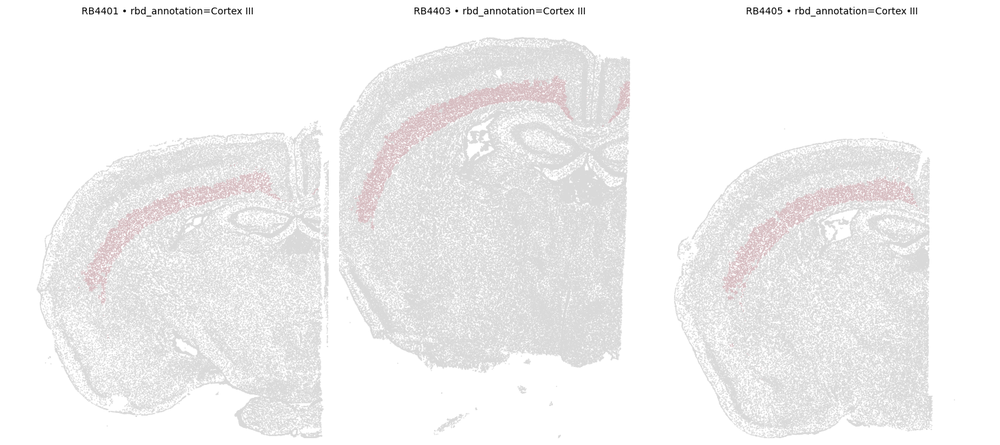

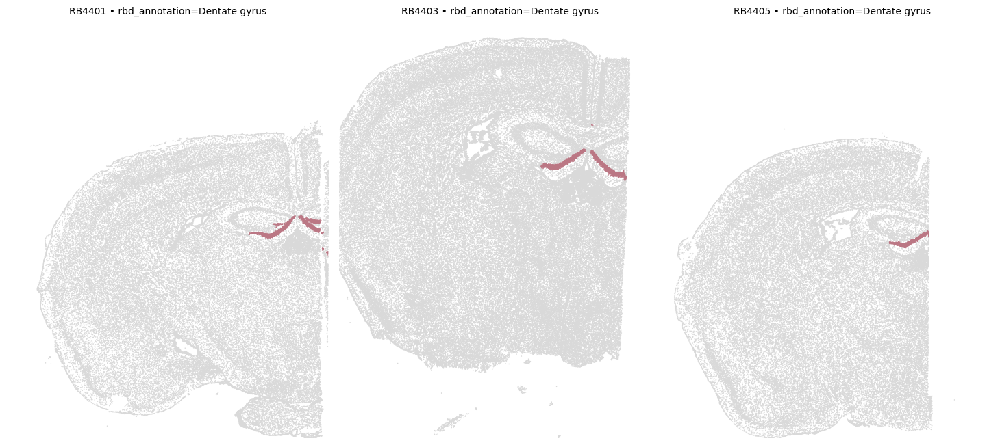

...

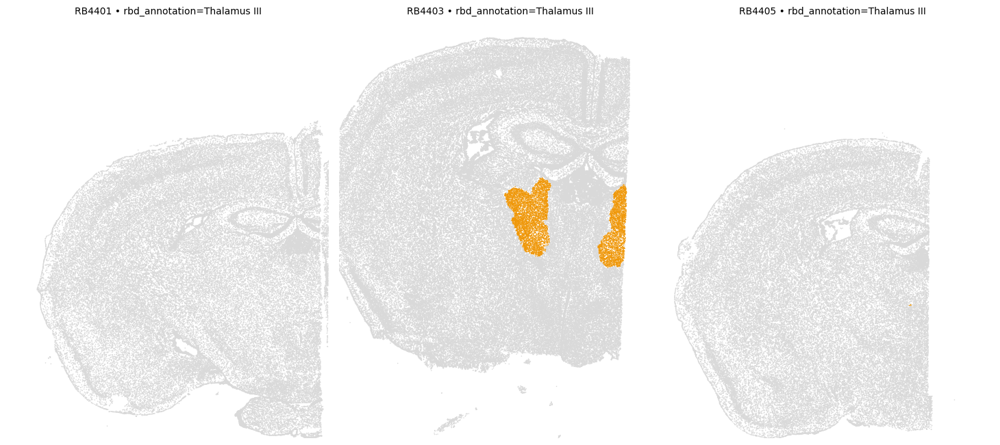

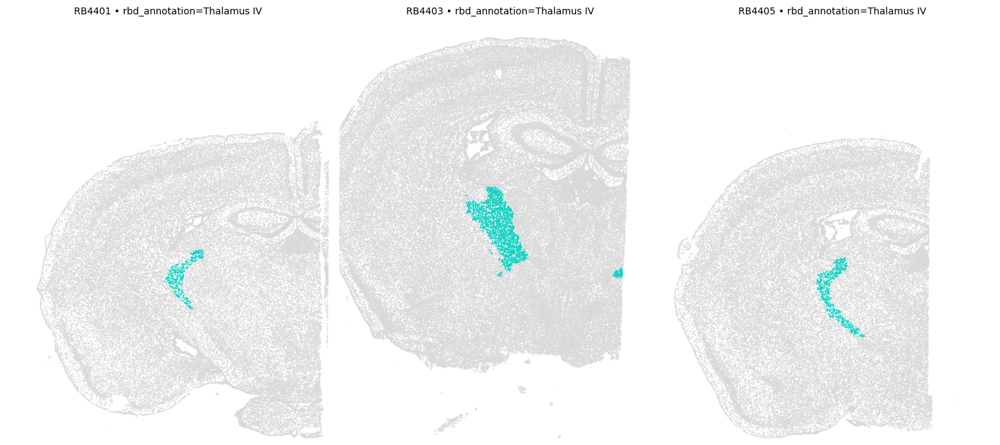

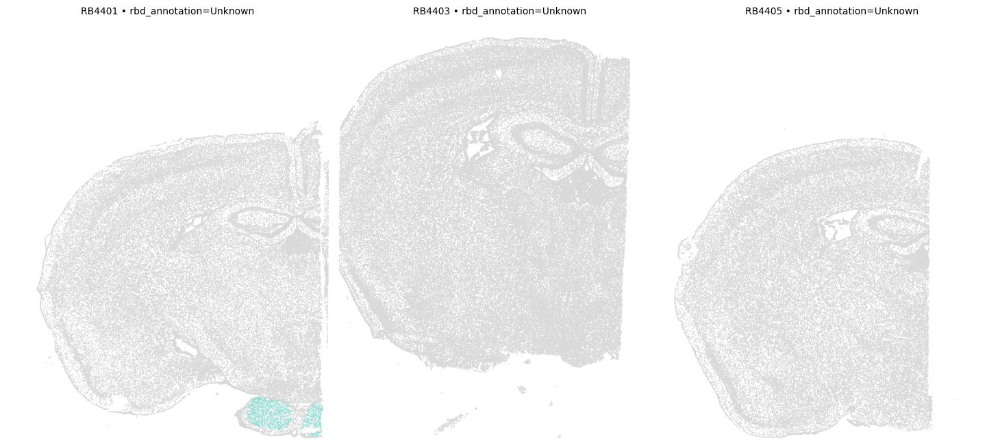

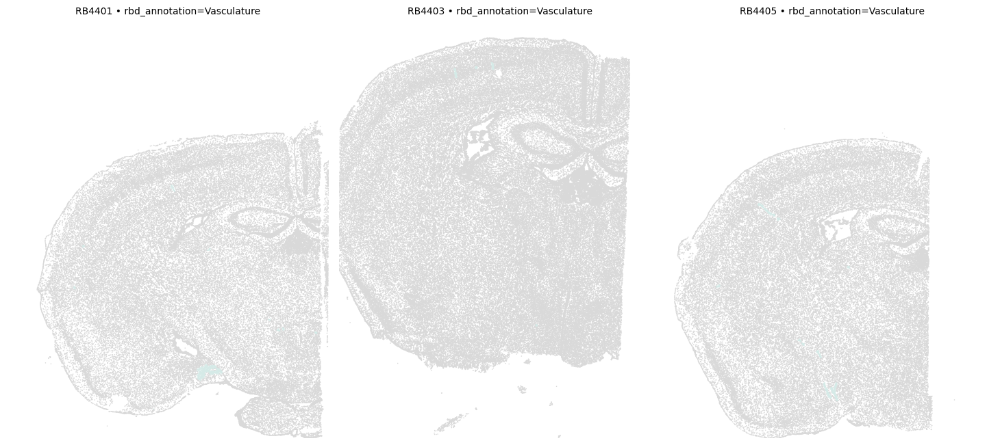

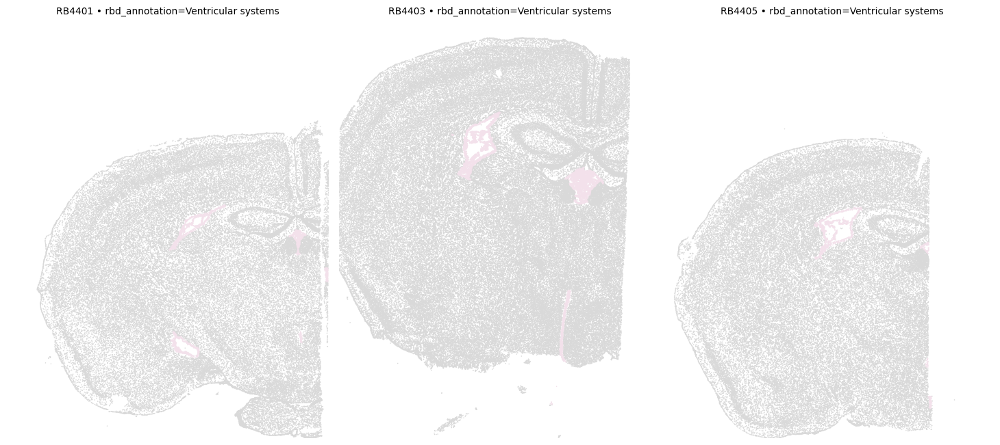

In [131]:
domain_key = "rbd_annotation"

for cl in adata.obs[domain_key].astype("category").cat.categories:
    fig, _ = plot_spatial_highlight(
        adata, color=domain_key, highlight=cl,
        groupby="sample_id", spot_size=20, cols=3, height=7,
        flip_y=True, fix_limits=True
    )
    plt.show()
    #fig.savefig(os.path.join(outdir, f"{domain_key}_cluster_{cl}.png"),
    #            dpi=300, bbox_inches="tight")
    #plt.close(fig)

Plotting Gfap...


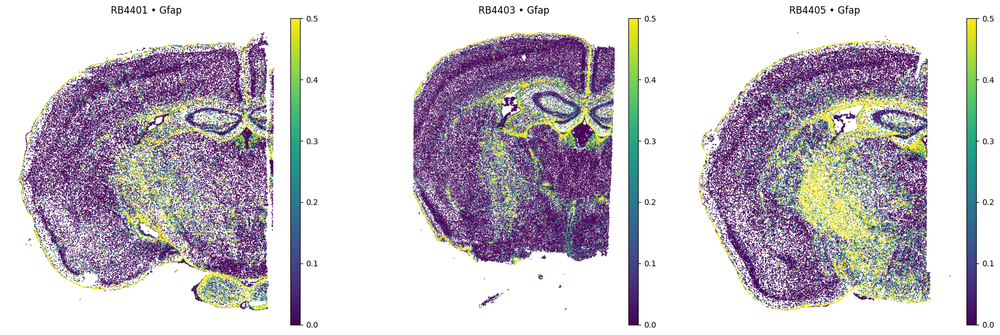

Plotting Serpina3n...


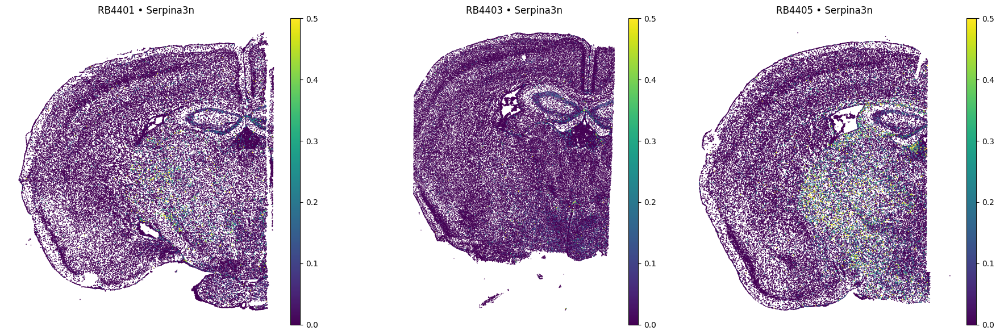

Plotting Ctss...


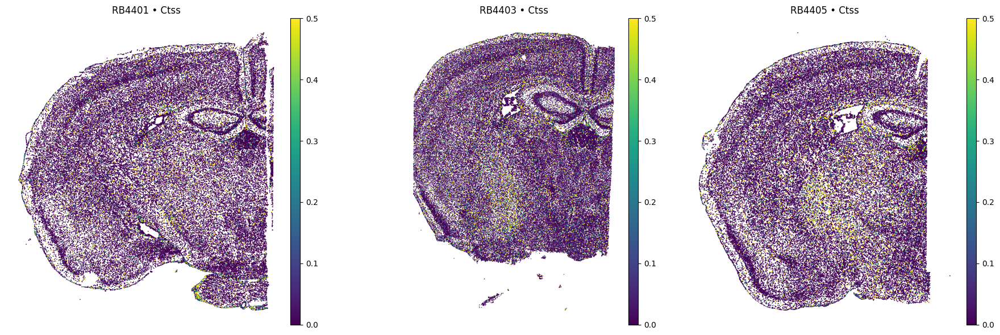

Plotting Atf4...


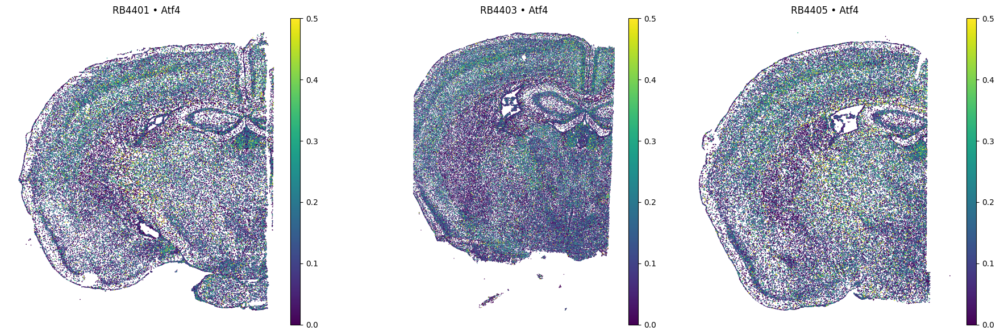

Plotting Cst7...


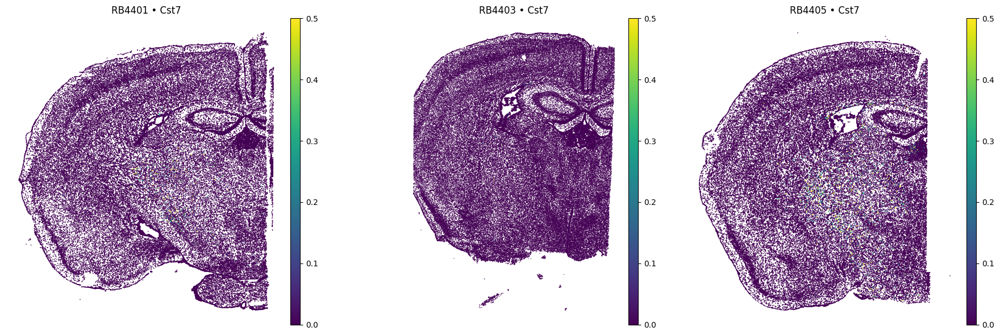

In [185]:
import scanpy as sc
import matplotlib.pyplot as plt
import os

# Example list of genes to plot
genes = ["Gfap", "Serpina3n", "Ctss",'Atf4','Cst7']

outdir = "../results/gene_expression_spatial"
os.makedirs(outdir, exist_ok=True)

for gene in genes:
    print(f"Plotting {gene}...")
    fig, axs = plt.subplots(1, len(adata.obs['sample_id'].unique()), figsize=(18, 6))
    
    if len(adata.obs['sample_id'].unique()) == 1:
        axs = [axs]  # handle single-sample case for consistent indexing
    
    for i, sid in enumerate(adata.obs['sample_id'].unique()):
        ad_sub = adata[adata.obs['sample_id'] == sid].copy()

        # Plot gene expression directly
        sc.pl.spatial(
            ad_sub,
            color=gene,
            spot_size=20,
            ax=axs[i],
            show=False,
            cmap="viridis",       # you can change to 'Reds', 'inferno', etc.
            vmin=0, vmax=0.5,    # or set explicit limits if needed
            frameon=False
        )
        axs[i].set_title(f"{sid} • {gene}")
        #axs[i].invert_yaxis()  # match orientation if needed
    
    plt.tight_layout()
    plt.show()
    # Optional: save
    # fig.savefig(os.path.join(outdir, f"{gene}_spatial.png"), dpi=300, bbox_inches="tight")
    # plt.close(fig)

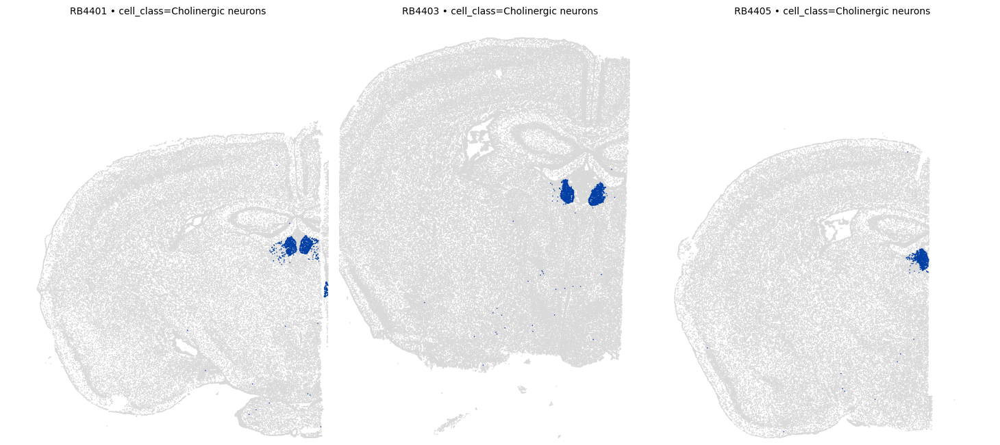

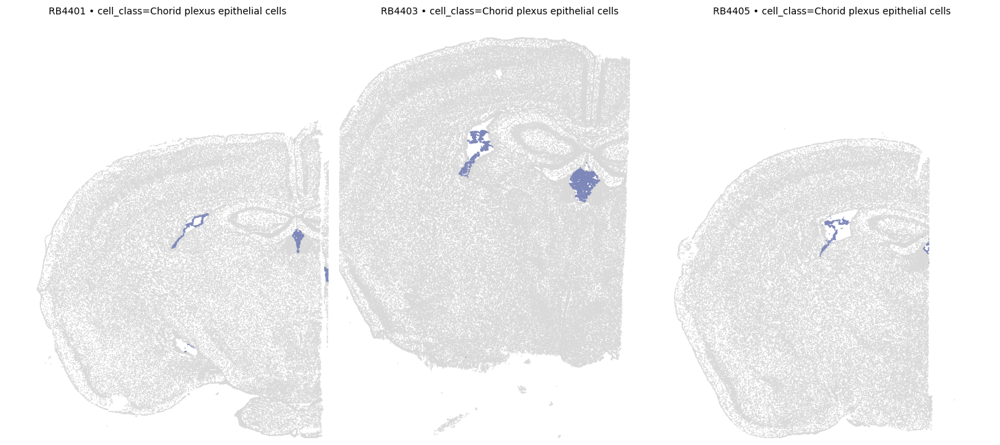

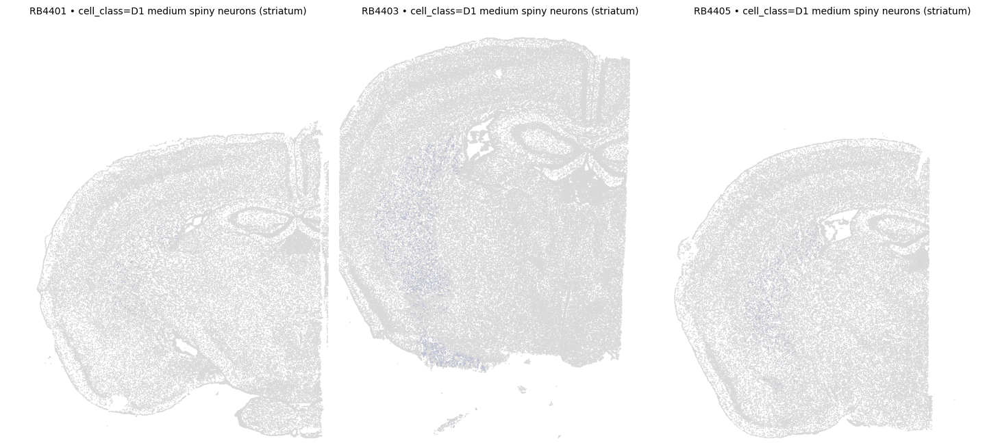

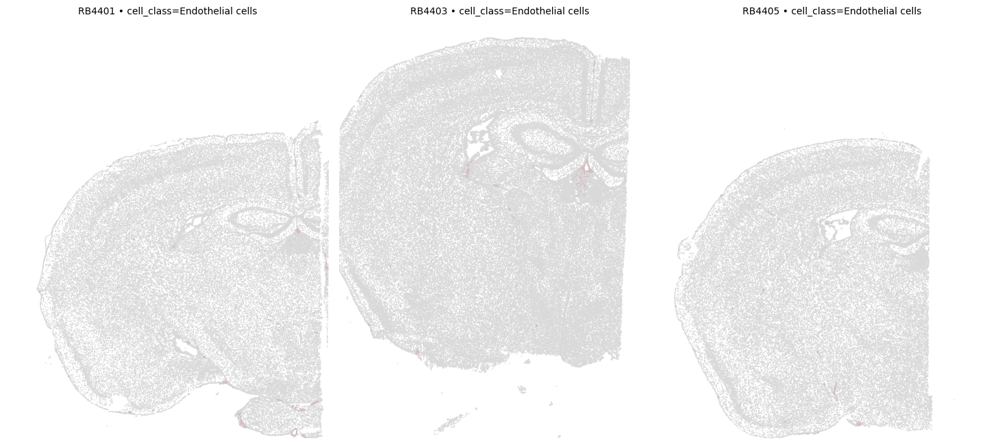

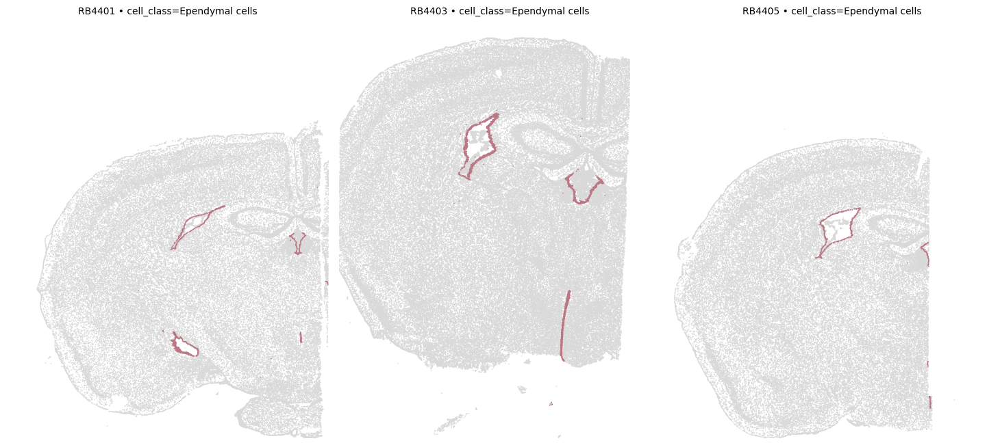

...

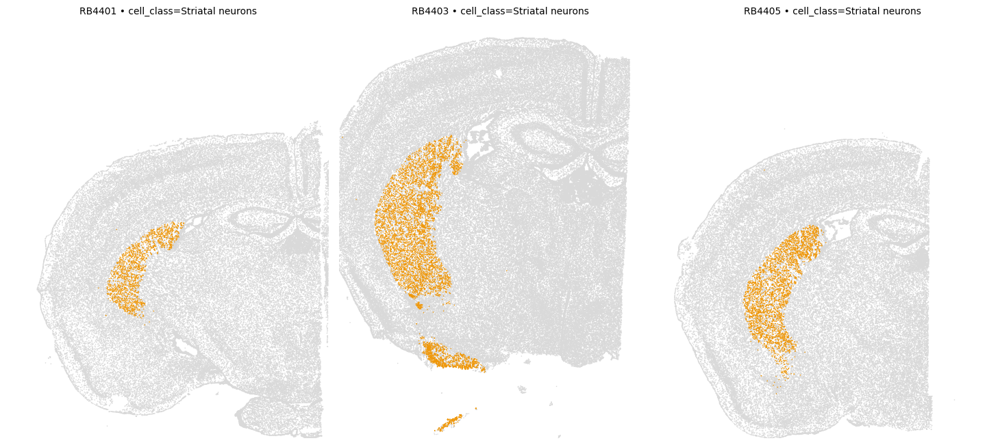

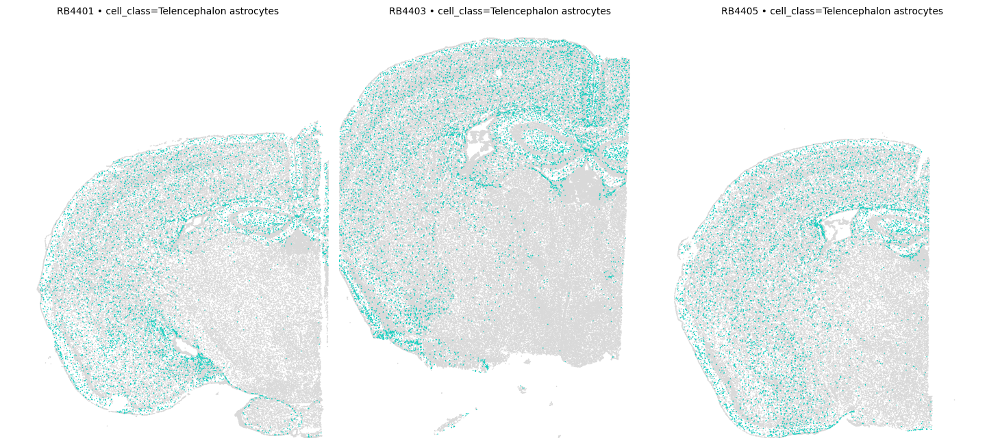

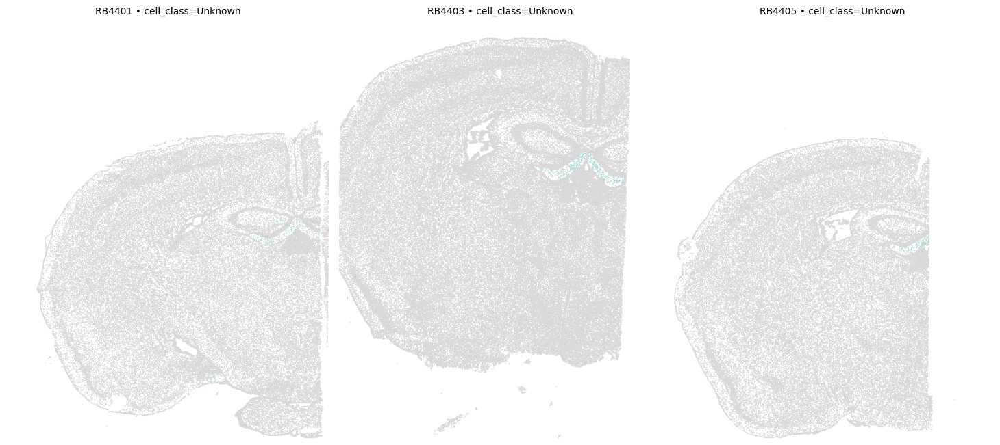

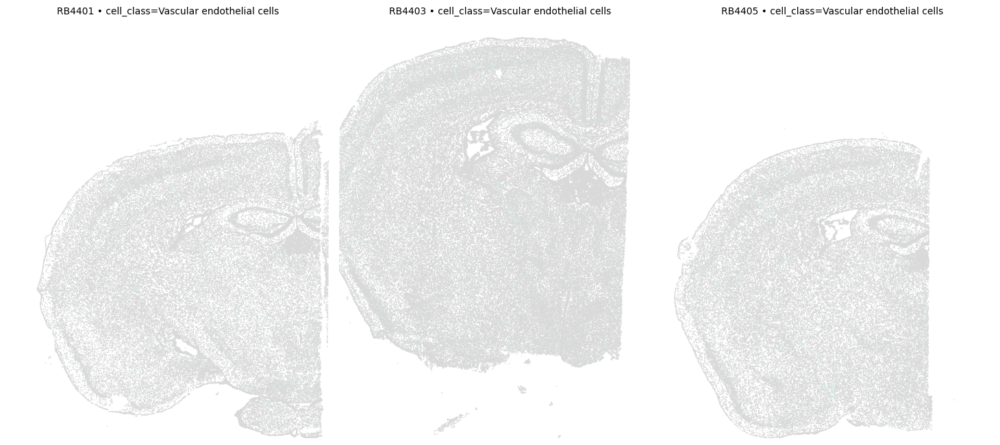

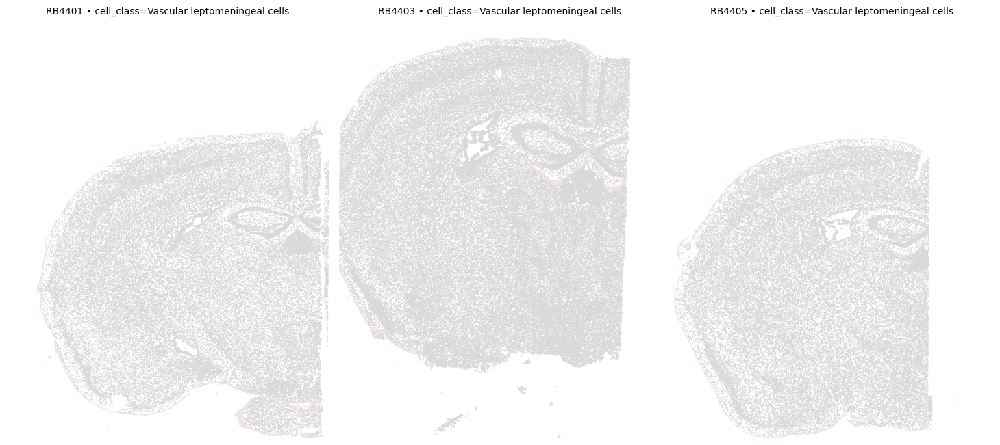

In [180]:
domain_key = "cell_class"

for cl in adata.obs[domain_key].astype("category").cat.categories:
    fig, _ = plot_spatial_highlight(
        adata, color=domain_key, highlight=cl,
        groupby="sample_id", spot_size=20, cols=3, height=7,
        flip_y=True, fix_limits=True
    )
    plt.show()
    #fig.savefig(os.path.join(outdir, f"{domain_key}_cluster_{cl}.png"),
    #            dpi=300, bbox_inches="tight")
    #plt.close(fig)

In [132]:
sc.tl.rank_genes_groups(adata, groupby="rbd_annotation")

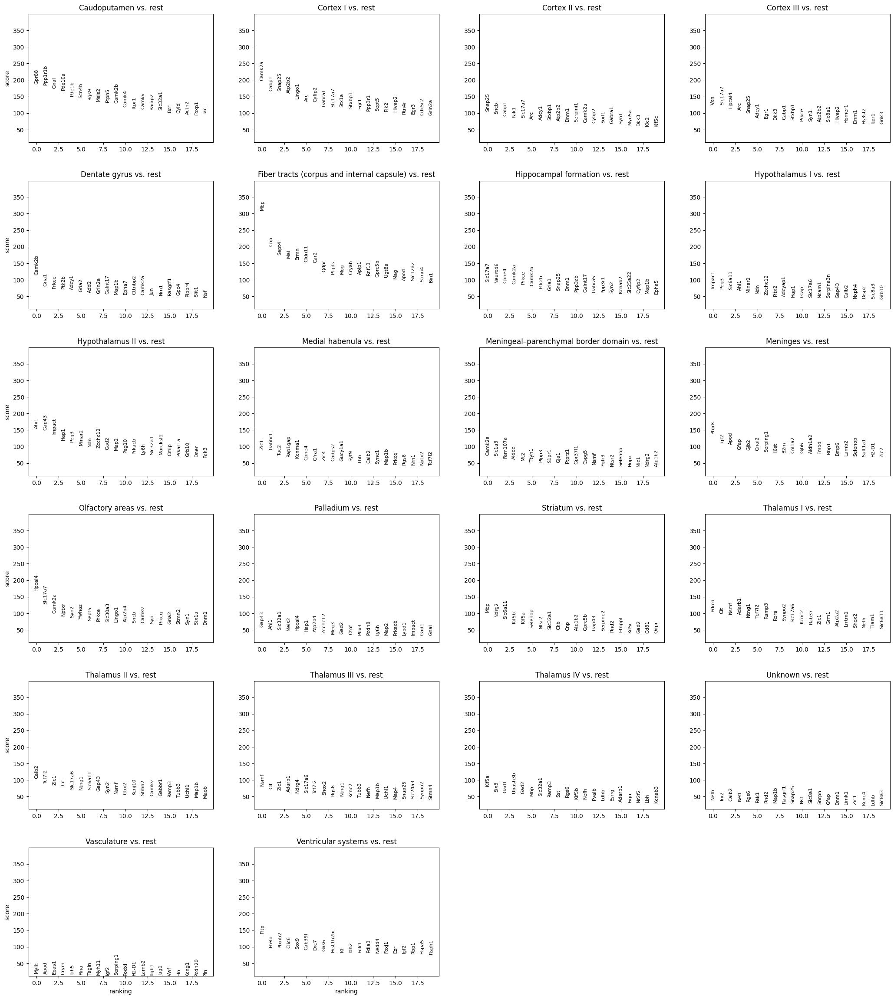

In [133]:
sc.pl.rank_genes_groups(adata)